# 🏠 House Prices — Advanced Regression Techniques
## Análisis Exploratorio (EDA)

> **Kaggle Competition** | Grupo  · Ciencia de Datos
 
> Objetivo: entender la distribución, calidad, relaciones y peculiaridades del dataset antes de modelar.

---
### Estructura del notebook
1. Carga de datos y vista general
2. Análisis del target `SalePrice`
3. Valores faltantes
4. Variables numéricas — distribución y correlación
5. Variables categóricas — frecuencias e impacto en precio
6. Outliers críticos
7. Análisis geográfico / por vecindario
8. Variables temporales
9. Matriz de correlación avanzada
10. Resumen ejecutivo y decisiones de feature engineering

In [23]:
# ─── 0. IMPORTACIONES ───────────────────────────────────────────────────────
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from scipy.stats import norm, skew, kurtosis

# Estilo profesional
plt.rcParams.update({
    'figure.dpi': 120,
    'figure.facecolor': 'white',
    'axes.facecolor': '#f8f9fa',
    'axes.grid': True,
    'grid.alpha': 0.4,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.family': 'sans-serif',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})
PALETTE = 'viridis'
COLOR_MAIN = '#2563EB'
COLOR_ACCENT = '#F59E0B'
COLOR_DANGER = '#EF4444'
COLOR_SUCCESS = '#10B981'

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', '{:.2f}'.format)
print('✅ Librerías cargadas correctamente')

✅ Librerías cargadas correctamente


---
## 1 · Carga de datos y vista general

In [24]:
# ─── 1.1 CARGA ──────────────────────────────────────────────────────────────
# Ajusta las rutas según donde hayas descargado los archivos de Kaggle
train = pd.read_csv('../data/train.csv')
test  = pd.read_csv('../data/test.csv')

print(f'Train: {train.shape[0]:,} filas × {train.shape[1]} columnas')
print(f'Test:  {test.shape[0]:,} filas × {test.shape[1]} columnas')
print(f'\nColumnas solo en train (target): {set(train.columns) - set(test.columns)}')
train.sample(10)

Train: 1,460 filas × 81 columnas
Test:  1,459 filas × 80 columnas

Columnas solo en train (target): {'SalePrice'}


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
274,275,20,RL,76.00,8314,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,Mitchel,Norm,Norm,1Fam,1Story,5,7,1982,1982,Gable,CompShg,HdBoard,ImStucc,NaN,0.00,TA,TA,CBlock,TA,TA,Gd,ALQ,546,Unf,0,270,816,GasA,TA,Y,SBrkr,816,0,0,816,0,0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1982.00,Unf,1,264,TA,TA,Y,168,0,0,0,0,0,NaN,NaN,NaN,0,6,2007,WD,Normal,124500
1155,1156,20,RL,90.00,10768,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Veenker,Norm,Norm,1Fam,1Story,5,8,1976,2004,Gable,CompShg,Plywood,Plywood,NaN,0.00,Gd,Gd,CBlock,Gd,TA,Gd,ALQ,1157,Unf,0,280,1437,GasA,TA,Y,SBrkr,1437,0,0,1437,1,0,2,0,3,1,Gd,6,Typ,1,Fa,Attchd,1976.00,RFn,2,528,TA,TA,Y,0,21,0,0,180,0,NaN,NaN,NaN,0,7,2007,WD,Normal,218000
1068,1069,160,RM,42.00,3964,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,MeadowV,Norm,Norm,TwnhsE,2Story,6,4,1973,1973,Gable,CompShg,CemntBd,CmentBd,NaN,0.00,TA,TA,CBlock,Gd,TA,No,ALQ,837,Unf,0,105,942,GasA,Gd,Y,SBrkr,1291,1230,0,2521,1,0,2,1,5,1,TA,10,Maj1,1,Gd,Attchd,1973.00,Fin,2,576,TA,TA,Y,728,20,0,0,0,0,NaN,GdPrv,NaN,0,6,2006,WD,Normal,151400
1281,1282,20,RL,50.00,8049,Pave,NaN,IR1,Lvl,AllPub,CulDSac,Gtl,Timber,Norm,Norm,1Fam,1Story,7,5,1990,1990,Hip,CompShg,HdBoard,HdBoard,BrkFace,54.00,TA,TA,CBlock,Gd,TA,No,ALQ,1053,Unf,0,256,1309,GasA,TA,Y,SBrkr,1339,0,0,1339,1,0,2,0,2,1,TA,6,Typ,1,TA,Attchd,1990.00,Fin,2,484,Gd,Gd,Y,0,58,0,0,90,0,NaN,NaN,NaN,0,7,2006,WD,Normal,180000
878,879,85,RL,88.00,11782,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Sawyer,Norm,Norm,1Fam,SFoyer,5,7,1961,1995,Gable,CompShg,HdBoard,HdBoard,NaN,0.00,TA,TA,CBlock,TA,TA,Av,ALQ,899,Unf,0,210,1109,GasA,TA,Y,SBrkr,1155,0,0,1155,1,0,1,0,3,1,Gd,6,Min2,0,NaN,Detchd,1987.00,Unf,2,576,TA,TA,Y,192,0,0,0,0,0,NaN,MnPrv,Shed,400,6,2010,WD,Normal,148000
675,676,160,RL,24.00,2289,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NPkVill,Norm,Norm,Twnhs,2Story,6,6,1978,1978,Gable,CompShg,Plywood,Brk Cmn,NaN,0.00,TA,TA,CBlock,TA,TA,No,ALQ,311,Unf,0,544,855,GasA,TA,Y,SBrkr,855,586,0,1441,0,0,2,1,3,1,TA,7,Typ,1,TA,Attchd,1978.00,Unf,2,440,TA,TA,Y,28,0,0,0,0,0,NaN,NaN,NaN,0,4,2009,WD,Normal,148500
1078,1079,120,RM,37.00,4435,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,TwnhsE,1Story,6,5,2004,2004,Gable,CompShg,VinylSd,VinylSd,BrkFace,169.00,Gd,TA,PConc,Gd,TA,Mn,GLQ,662,Unf,0,186,848,GasA,Ex,Y,SBrkr,848,0,0,848,1,0,1,0,1,1,Gd,3,Typ,1,Gd,Attchd,2004.00,RFn,2,420,TA,TA,Y,140,0,0,0,0,0,NaN,NaN,NaN,0,5,2006,WD,Normal,155900
616,617,60,RL,NaN,7861,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,6,5,2002,2003,Gable,CompShg,VinylSd,VinylSd,NaN,0.00,Gd,TA,PConc,Gd,TA,No,GLQ,457,Unf,0,326,783,GasA,Ex,Y,SBrkr,807,702,0,1509,1,0,2,1,3,1,Gd,7,Typ,1,Gd,Attchd,2002.00,Fin,2,393,TA,TA,Y,100,75,0,0,0,0,NaN,NaN,NaN,0,6,2006,WD,Normal,183200
505,506,90,RM,60.00,7596,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,OldTown,Artery,Norm,Duplex,2Story,5,5,1952,1952,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,360.00,TA,TA,CBlock,TA,TA,No,Unf,0,Unf,0,960,960,GasA,Gd,Y,SBrkr,960,1000,0,1960,0,0,2,0,4,2,TA,10,Typ,0,NaN,Detchd,1952.00,Unf,2,400,TA,TA,N,0,0,0,0,0,0,NaN,NaN,NaN,0,7,2009,COD,Normal,124500
1447,1448,60,RL,80.00,10000,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,8,5,1995,1996,Gable,CompShg,VinylSd,VinylSd,Brk

In [25]:
# ─── 1.2 TIPOS DE DATOS ─────────────────────────────────────────────────────
num_cols  = train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols  = train.select_dtypes(include=['object']).columns.tolist()

# Quitamos el target de las numéricas para el análisis de features
num_features = [c for c in num_cols if c not in ['SalePrice', 'Id']]

print(f'Variables numéricas : {len(num_cols)}  (features: {len(num_features)})')
print(f'Variables categóricas: {len(cat_cols)}')
print(f'\nVariables numéricas:\n{num_features}')
print(f'\nVariables categóricas:\n{cat_cols}')

Variables numéricas : 38  (features: 36)
Variables categóricas: 43

Variables numéricas:
['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']

Variables categóricas:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir',

In [26]:
# ─── 1.3 ESTADÍSTICAS GENERALES ─────────────────────────────────────────────
print('=== ESTADÍSTICAS DESCRIPTIVAS — VARIABLES NUMÉRICAS ===')
train[num_features + ['SalePrice']].describe().T.style.background_gradient(cmap='Blues', subset=['mean','std'])

=== ESTADÍSTICAS DESCRIPTIVAS — VARIABLES NUMÉRICAS ===


,count,mean,std,min,25%,50%,75%,max
MSSubClass,1460.000000,56.897260,42.300571,20.000000,20.000000,50.000000,70.000000,190.000000
LotFrontage,1201.000000,70.049958,24.284752,21.000000,59.000000,69.000000,80.000000,313.000000
LotArea,1460.000000,10516.828082,9981.264932,1300.000000,7553.500000,9478.500000,11601.500000,215245.000000
OverallQual,1460.000000,6.099315,1.382997,1.000000,5.000000,6.000000,7.000000,10.000000
OverallCond,1460.000000,5.575342,1.112799,1.000000,5.000000,5.000000,6.000000,9.000000
YearBuilt,1460.000000,1971.267808,30.202904,1872.000000,1954.000000,1973.000000,2000.000000,2010.000000
YearRemodAdd,1460.000000,1984.865753,20.645407,1950.000000,1967.000000,1994.000000,2004.000000,2010.000000
MasVnrArea,1452.000000,103.685262,181.066207,0.000000,0.000000,0.000000,166.000000,1600.000000
BsmtFinSF1,1460.000000,443.639726,456.098091,0.000000,0.000000,383.500000,712.250000,5644.000000
BsmtFinSF2,1460.000000,46.549315,161.319273,0.000000,0.000000,0.000000,0.000000,1474.000000


---
## 2 · Análisis del Target: `SalePrice`
> La distribución del target determina la transformación que debemos aplicar.

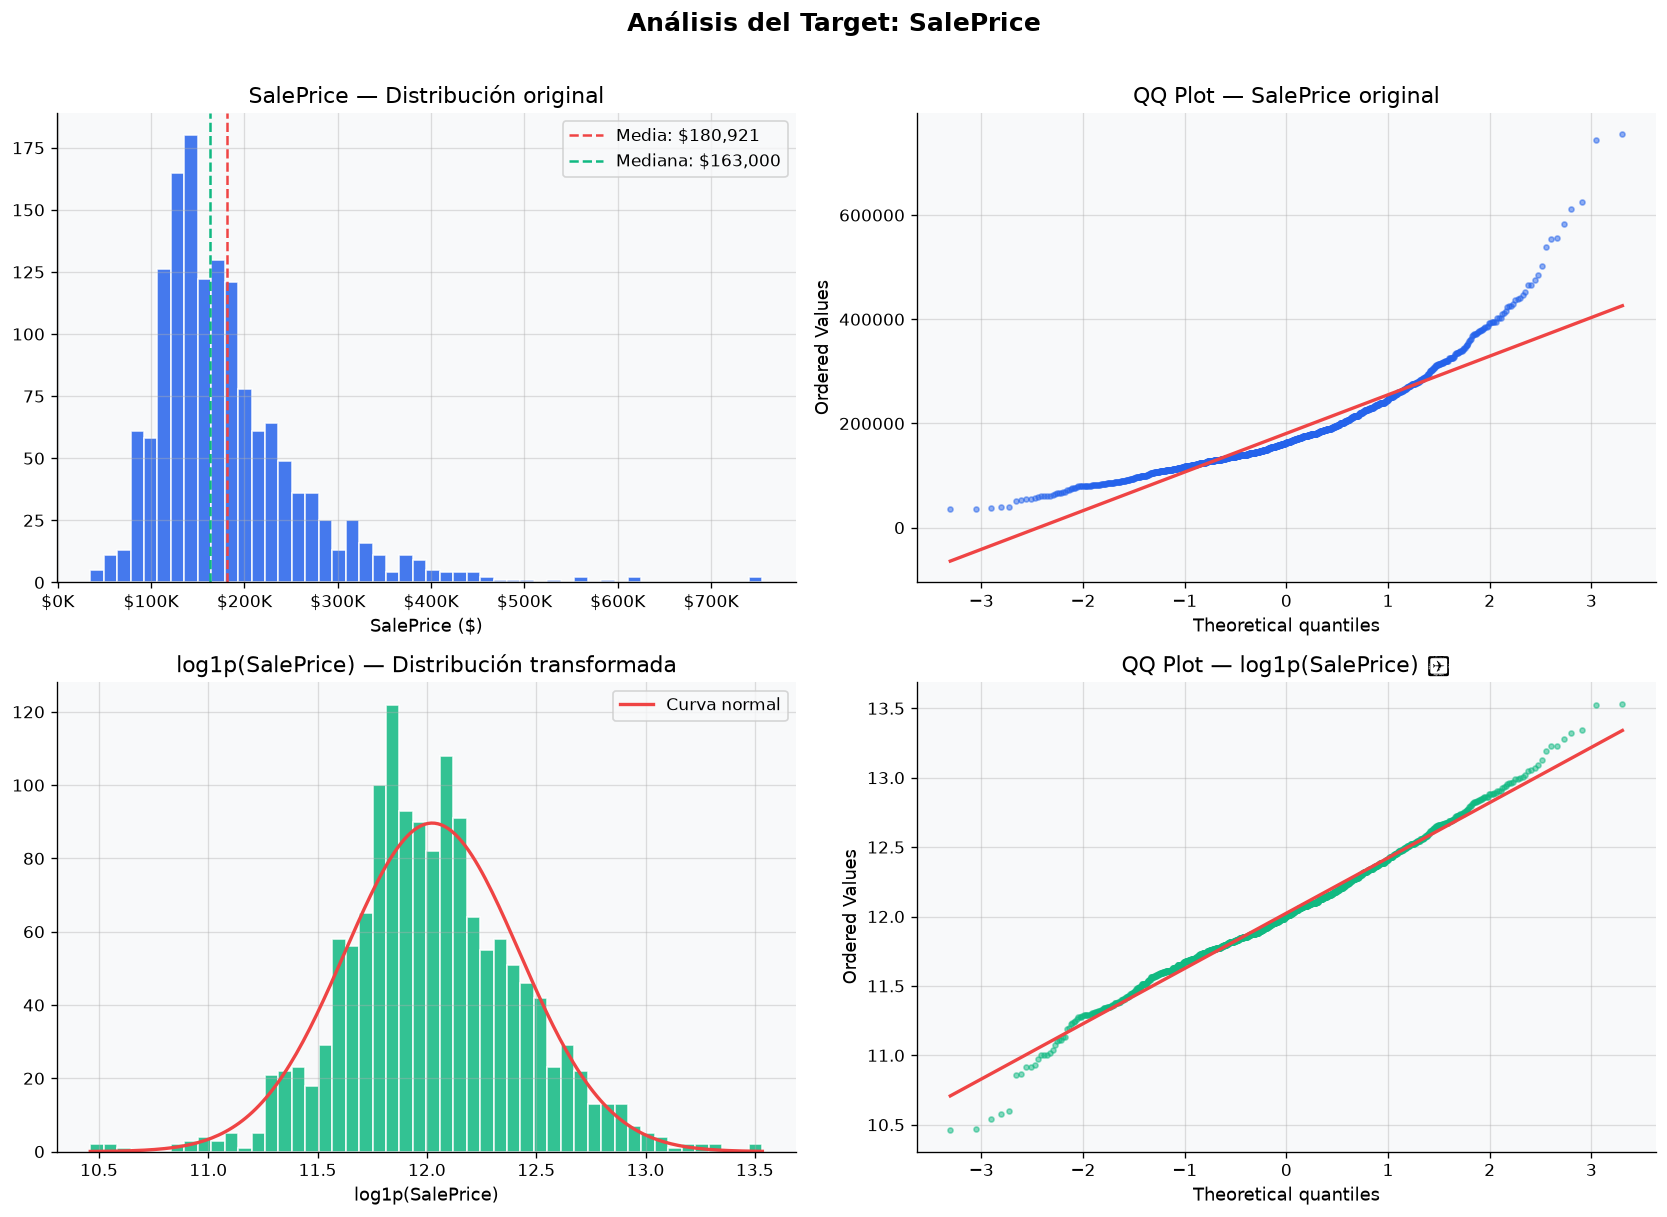


📊 ESTADÍSTICAS DEL TARGET
  Media:     $     180,921   |  log: 12.0241
  Mediana:   $     163,000   |  log: 12.0015
  Desv Est:  $      79,443   |  log: 0.3994
  Skewness:        1.8809   |  log: 0.1212  (objetivo: ~0)
  Kurtosis:        6.5098   |  log: 0.8026  (objetivo: ~0)

✅ CONCLUSIÓN: usar np.log1p(SalePrice) como target para todos los modelos
   Al predecir, aplicar np.expm1() para revertir la transformación


In [27]:
# ─── 2.1 DISTRIBUCIÓN ORIGINAL vs LOG ───────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Análisis del Target: SalePrice', fontsize=15, fontweight='bold', y=1.01)

sp = train['SalePrice']
sp_log = np.log1p(sp)

# --- Histograma original ---
ax = axes[0, 0]
ax.hist(sp, bins=50, color=COLOR_MAIN, edgecolor='white', alpha=0.85)
ax.set_title('SalePrice — Distribución original')
ax.set_xlabel('SalePrice ($)')
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))
ax.axvline(sp.mean(), color=COLOR_DANGER, linestyle='--', label=f'Media: ${sp.mean():,.0f}')
ax.axvline(sp.median(), color=COLOR_SUCCESS, linestyle='--', label=f'Mediana: ${sp.median():,.0f}')
ax.legend()

# --- QQ Plot original ---
ax = axes[0, 1]
stats.probplot(sp, dist='norm', plot=ax)
ax.set_title('QQ Plot — SalePrice original')
ax.get_lines()[0].set(color=COLOR_MAIN, markersize=3, alpha=0.5)
ax.get_lines()[1].set(color=COLOR_DANGER, linewidth=2)

# --- Histograma log-transformado ---
ax = axes[1, 0]
ax.hist(sp_log, bins=50, color=COLOR_SUCCESS, edgecolor='white', alpha=0.85)
mu, sigma = sp_log.mean(), sp_log.std()
x_range = np.linspace(sp_log.min(), sp_log.max(), 200)
ax.plot(x_range, norm.pdf(x_range, mu, sigma) * len(sp_log) * (sp_log.max()-sp_log.min())/50,
        color=COLOR_DANGER, linewidth=2, label='Curva normal')
ax.set_title('log1p(SalePrice) — Distribución transformada')
ax.set_xlabel('log1p(SalePrice)')
ax.legend()

# --- QQ Plot log ---
ax = axes[1, 1]
stats.probplot(sp_log, dist='norm', plot=ax)
ax.set_title('QQ Plot — log1p(SalePrice) ✅')
ax.get_lines()[0].set(color=COLOR_SUCCESS, markersize=3, alpha=0.5)
ax.get_lines()[1].set(color=COLOR_DANGER, linewidth=2)

plt.tight_layout()
plt.savefig('../img/eda_01_target_distribution.png', bbox_inches='tight', dpi=120)
plt.show()

print(f'\n📊 ESTADÍSTICAS DEL TARGET')
print(f'  Media:     ${sp.mean():>12,.0f}   |  log: {sp_log.mean():.4f}')
print(f'  Mediana:   ${sp.median():>12,.0f}   |  log: {sp_log.median():.4f}')
print(f'  Desv Est:  ${sp.std():>12,.0f}   |  log: {sp_log.std():.4f}')
print(f'  Skewness:  {skew(sp):>12.4f}   |  log: {skew(sp_log):.4f}  (objetivo: ~0)')
print(f'  Kurtosis:  {kurtosis(sp):>12.4f}   |  log: {kurtosis(sp_log):.4f}  (objetivo: ~0)')
print(f'\n✅ CONCLUSIÓN: usar np.log1p(SalePrice) como target para todos los modelos')
print(f'   Al predecir, aplicar np.expm1() para revertir la transformación')

---
## 3 · Análisis de Valores Faltantes

In [28]:
# ─── 3.1 MAPA DE NULOS ──────────────────────────────────────────────────────
def missing_report(df, label='Train'):
    missing = df.isnull().sum()
    missing = missing[missing > 0].sort_values(ascending=False)
    missing_pct = (missing / len(df) * 100).round(2)
    report = pd.DataFrame({'Nulos': missing, 'Porcentaje': missing_pct})
    # Clasificación por tipo de imputación
    none_cols_known = ['PoolQC','MiscFeature','Alley','Fence','FireplaceQu',
                       'GarageType','GarageFinish','GarageQual','GarageCond',
                       'BsmtQual','BsmtCond','BsmtExposure','BsmtFinType1',
                       'BsmtFinType2','MasVnrType']
    report['Estrategia'] = report.index.map(
        lambda c: '"None" — no tiene' if c in none_cols_known
        else ('0 — no tiene' if 'Bsmt' in c or 'Garage' in c or 'Mas' in c
        else ('Mediana' if df[c].dtype != 'object' else 'Moda')))
    return report

miss_train = missing_report(train, 'Train')
miss_test  = missing_report(test,  'Test')

print(f'Variables con nulos en TRAIN: {len(miss_train)}')
print(f'Variables con nulos en TEST:  {len(miss_test)}')
display(miss_train.style.background_gradient(cmap='Reds', subset=['Porcentaje']))

Variables con nulos en TRAIN: 19
Variables con nulos en TEST:  33


,Nulos,Porcentaje,Estrategia
PoolQC,1453,99.520000,"""None"" — no tiene"
MiscFeature,1406,96.300000,"""None"" — no tiene"
Alley,1369,93.770000,"""None"" — no tiene"
Fence,1179,80.750000,"""None"" — no tiene"
MasVnrType,872,59.730000,"""None"" — no tiene"
FireplaceQu,690,47.260000,"""None"" — no tiene"
LotFrontage,259,17.740000,Mediana
GarageType,81,5.550000,"""None"" — no tiene"
GarageYrBlt,81,5.550000,0 — no tiene
GarageFinish,81,5.550000,"""None"" — no tiene"


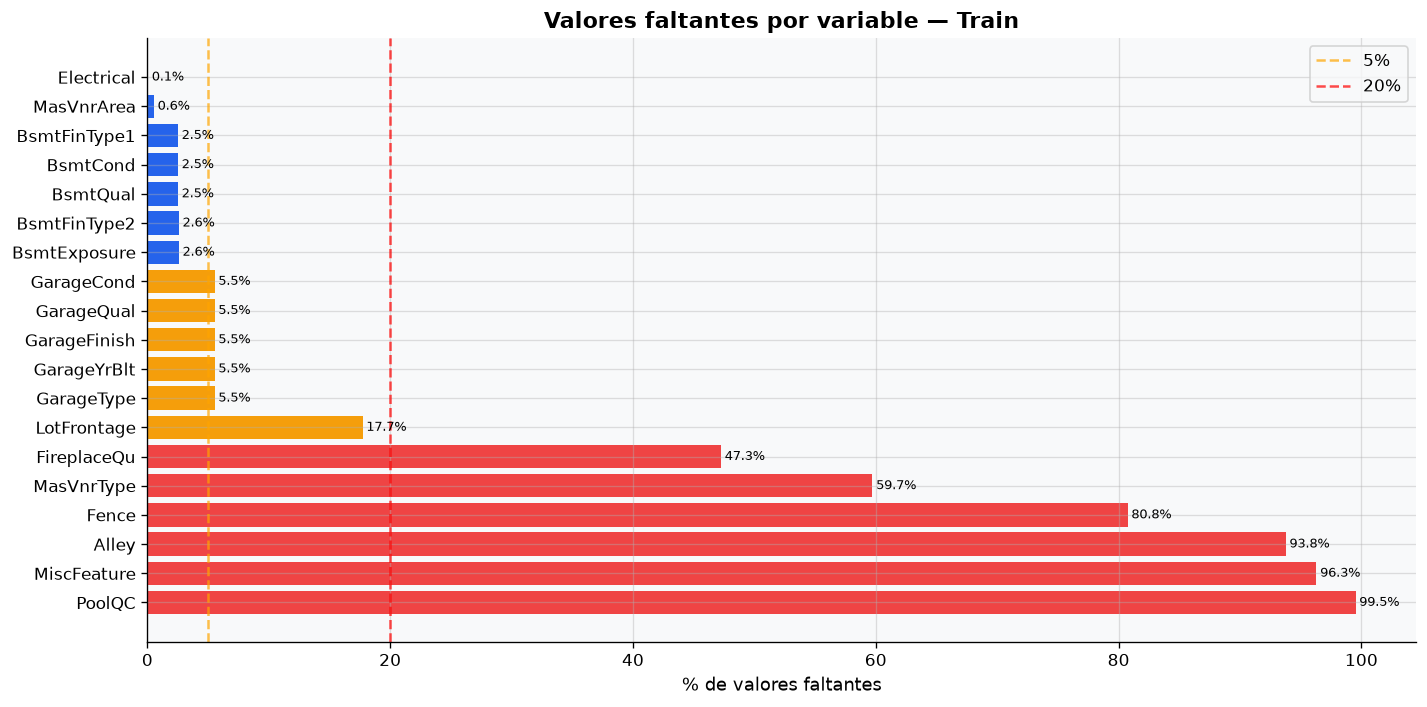


🔑 DECISIONES DE IMPUTACIÓN:
  🔴 >20% nulos: PoolQC, MiscFeature, Alley, Fence → "None" (la mayoría no tiene)
  🟡  5-20%: FireplaceQu, GarageXxx, BsmtXxx    → "None" o 0 según tipo
  🔵  <5%:  LotFrontage, MasVnrType, Electrical → mediana/moda


In [29]:
# ─── 3.2 GRÁFICO DE NULOS ───────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.barh(miss_train.index, miss_train['Porcentaje'],
               color=[COLOR_DANGER if p > 20 else COLOR_ACCENT if p > 5 else COLOR_MAIN
                      for p in miss_train['Porcentaje']])
ax.set_xlabel('% de valores faltantes')
ax.set_title('Valores faltantes por variable — Train', fontweight='bold')
ax.axvline(5,  color='orange', linestyle='--', alpha=0.7, label='5%')
ax.axvline(20, color='red',    linestyle='--', alpha=0.7, label='20%')

for bar, pct in zip(bars, miss_train['Porcentaje']):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f'{pct:.1f}%', va='center', fontsize=8)

ax.legend()
plt.tight_layout()
plt.savefig('../img/seda_02_missing_values.png', bbox_inches='tight', dpi=120)
plt.show()

print('\n🔑 DECISIONES DE IMPUTACIÓN:')
print('  🔴 >20% nulos: PoolQC, MiscFeature, Alley, Fence → "None" (la mayoría no tiene)')
print('  🟡  5-20%: FireplaceQu, GarageXxx, BsmtXxx    → "None" o 0 según tipo')
print('  🔵  <5%:  LotFrontage, MasVnrType, Electrical → mediana/moda')

---
## 4 · Variables Numéricas — Distribución y Correlación con SalePrice

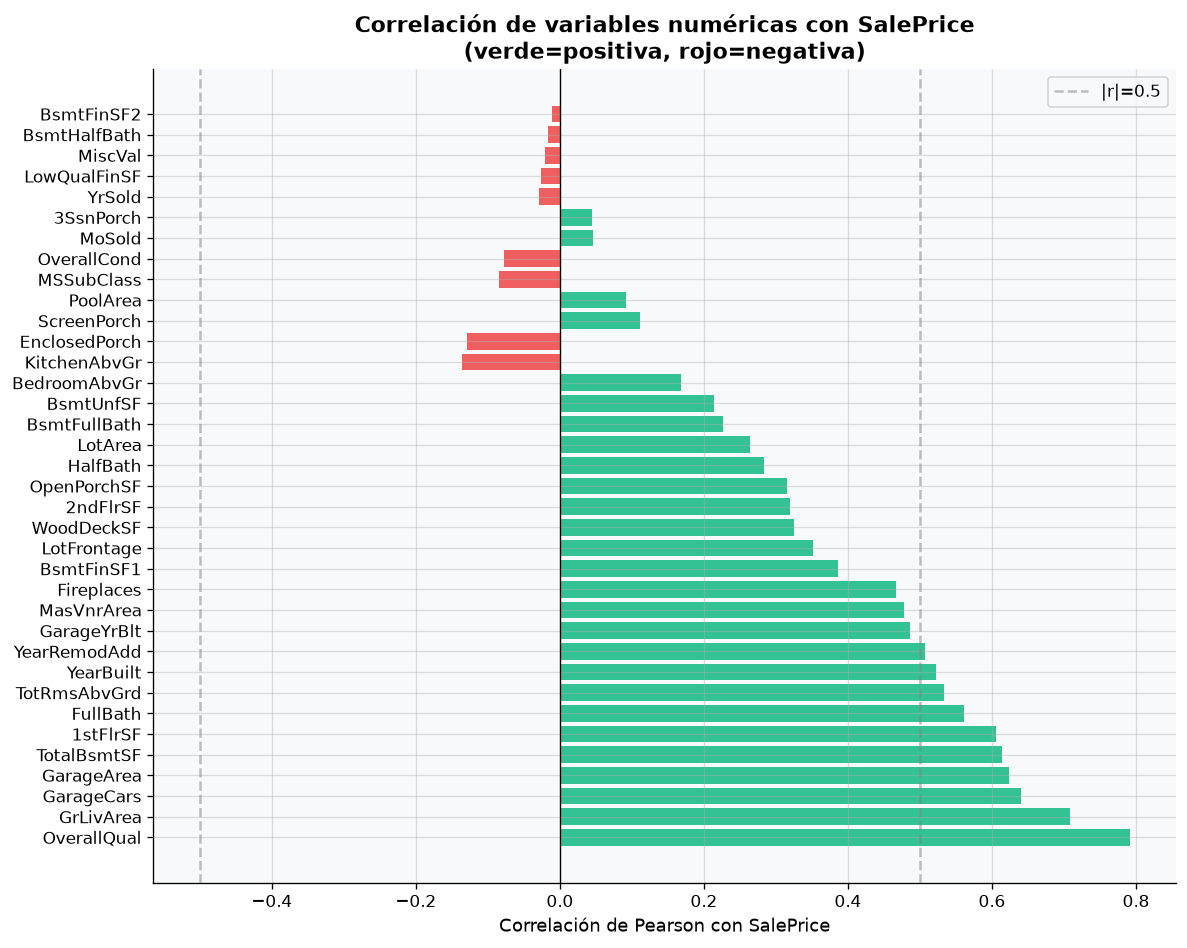


🏆 TOP 10 variables más correlacionadas con SalePrice:
  ▲ OverallQual          r = +0.791
  ▲ GrLivArea            r = +0.709
  ▲ GarageCars           r = +0.640
  ▲ GarageArea           r = +0.623
  ▲ TotalBsmtSF          r = +0.614
  ▲ 1stFlrSF             r = +0.606
  ▲ FullBath             r = +0.561
  ▲ TotRmsAbvGrd         r = +0.534
  ▲ YearBuilt            r = +0.523
  ▲ YearRemodAdd         r = +0.507


In [30]:
# ─── 4.1 CORRELACIÓN CON SALEPRICE ──────────────────────────────────────────
corr_with_target = train[num_features + ['SalePrice']].corr()['SalePrice'].drop('SalePrice')
corr_sorted = corr_with_target.abs().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
colors = [COLOR_SUCCESS if c > 0 else COLOR_DANGER
          for c in corr_with_target[corr_sorted.index]]
ax.barh(corr_sorted.index, corr_with_target[corr_sorted.index], color=colors, alpha=0.85)
ax.axvline(0, color='black', linewidth=0.8)
ax.axvline(0.5,  color='gray', linestyle='--', alpha=0.5, label='|r|=0.5')
ax.axvline(-0.5, color='gray', linestyle='--', alpha=0.5)
ax.set_xlabel('Correlación de Pearson con SalePrice')
ax.set_title('Correlación de variables numéricas con SalePrice\n(verde=positiva, rojo=negativa)', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('../img/eda_03_correlacion_target.png', bbox_inches='tight', dpi=120)
plt.show()

print('\n🏆 TOP 10 variables más correlacionadas con SalePrice:')
for feat, val in corr_sorted.head(10).items():
    direction = '▲' if corr_with_target[feat] > 0 else '▼'
    print(f'  {direction} {feat:<20} r = {corr_with_target[feat]:+.3f}')

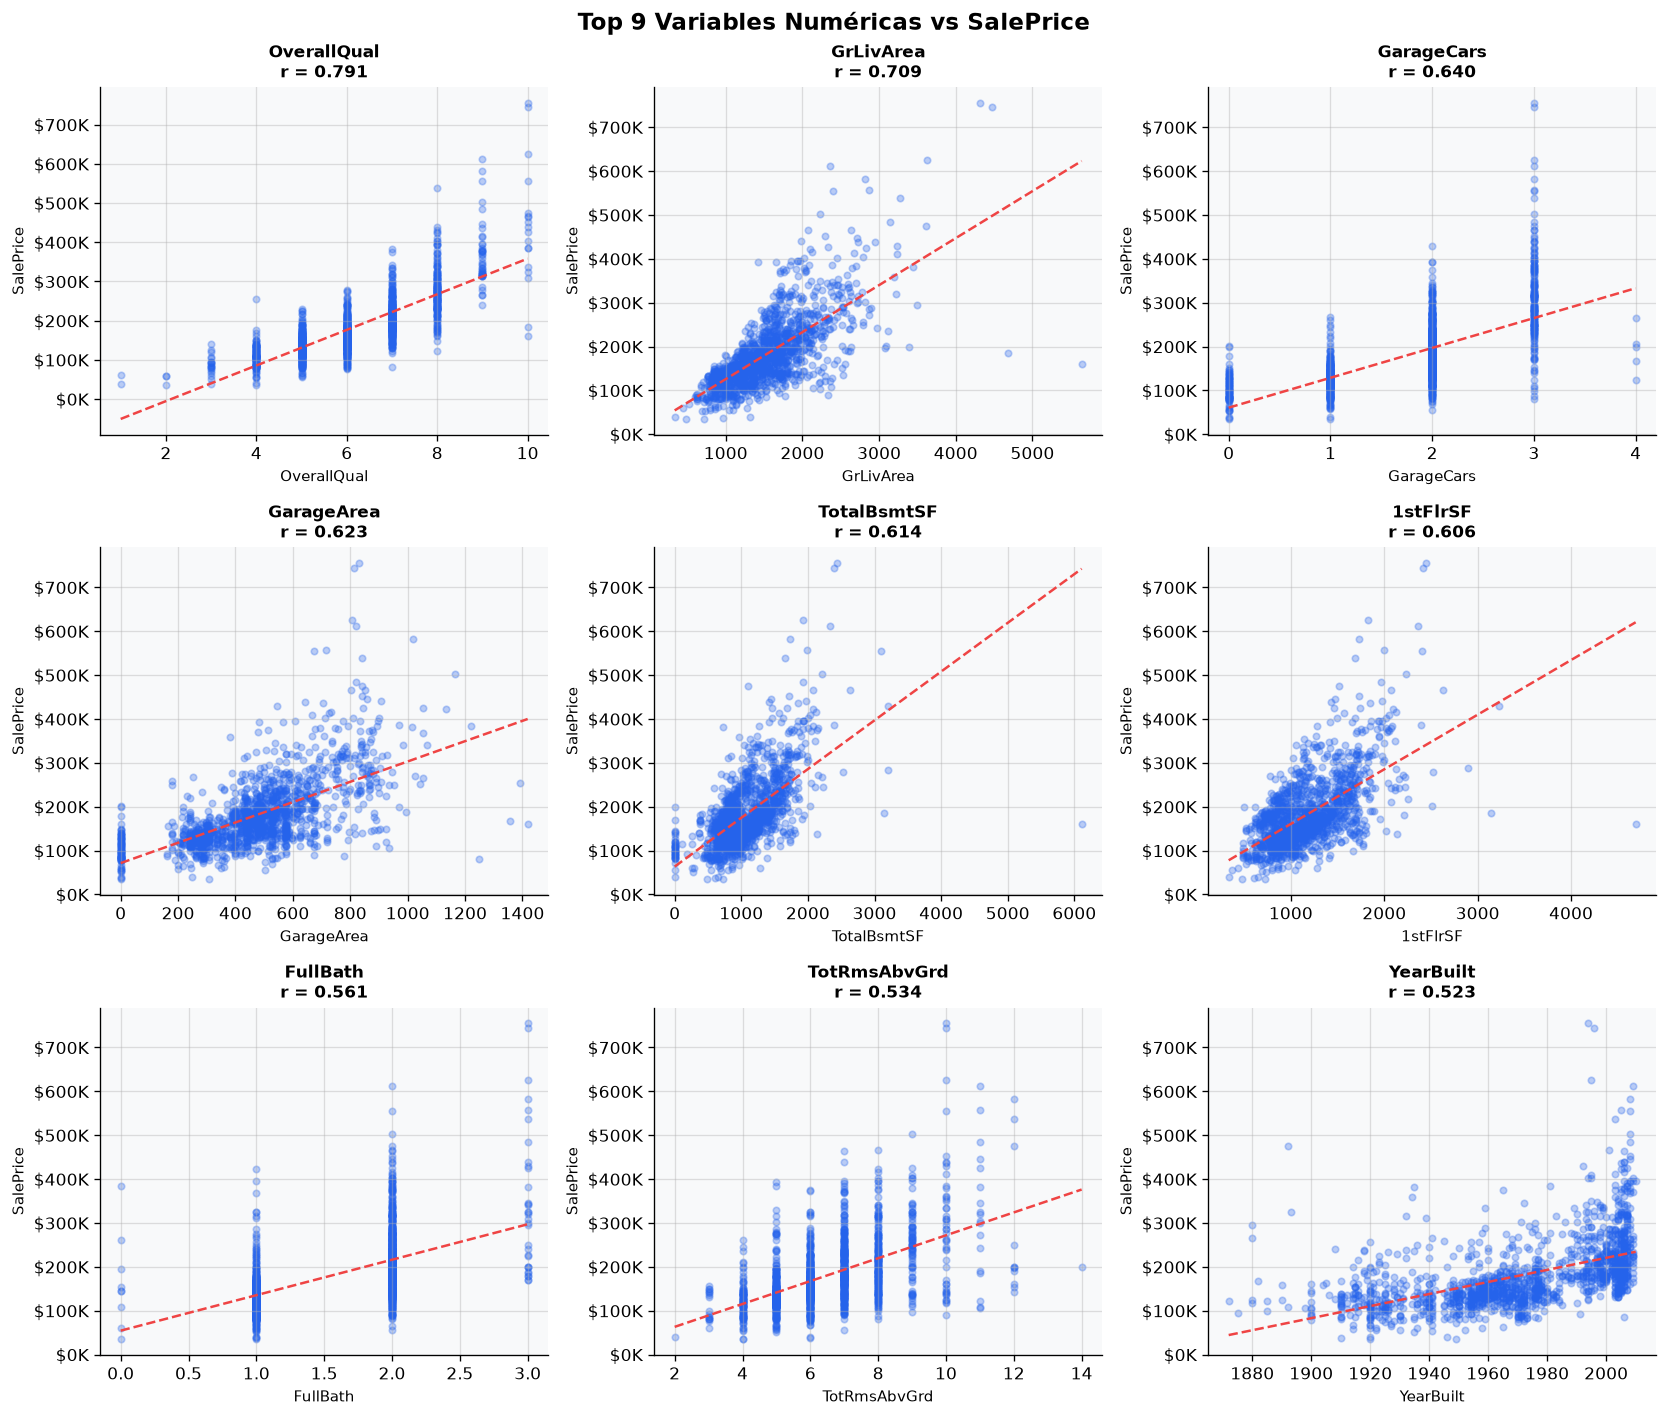

In [31]:
# ─── 4.2 SCATTER PLOTS — TOP 9 VARIABLES NUMÉRICAS ─────────────────────────
top9 = corr_sorted.head(9).index.tolist()

fig, axes = plt.subplots(3, 3, figsize=(14, 12))
fig.suptitle('Top 9 Variables Numéricas vs SalePrice', fontsize=14, fontweight='bold')

for ax, feat in zip(axes.ravel(), top9):
    r = corr_with_target[feat]
    ax.scatter(train[feat], train['SalePrice'],
               alpha=0.3, s=15, color=COLOR_MAIN)
    # Línea de tendencia
    mask = train[feat].notna()
    z = np.polyfit(train.loc[mask, feat], train.loc[mask, 'SalePrice'], 1)
    p = np.poly1d(z)
    x_line = np.linspace(train[feat].min(), train[feat].max(), 100)
    ax.plot(x_line, p(x_line), color=COLOR_DANGER, linewidth=1.5, linestyle='--')
    ax.set_xlabel(feat, fontsize=9)
    ax.set_ylabel('SalePrice', fontsize=9)
    ax.set_title(f'{feat}\nr = {r:.3f}', fontsize=10, fontweight='bold')
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))

plt.tight_layout()
plt.savefig('../img/eda_04_scatter_top9.png', bbox_inches='tight', dpi=120)
plt.show()

Variables con |skewness| > 0.75: 21 (candidatas a log-transform)
MiscVal         24.45
PoolArea        14.81
LotArea         12.20
3SsnPorch       10.29
LowQualFinSF     9.00
KitchenAbvGr     4.48
BsmtFinSF2       4.25
ScreenPorch      4.12
BsmtHalfBath     4.10
EnclosedPorch    3.09
MasVnrArea       2.67
OpenPorchSF      2.36
LotFrontage      2.16
BsmtFinSF1       1.68
WoodDeckSF       1.54
TotalBsmtSF      1.52
MSSubClass       1.41
1stFlrSF         1.38
GrLivArea        1.37
BsmtUnfSF        0.92
2ndFlrSF         0.81


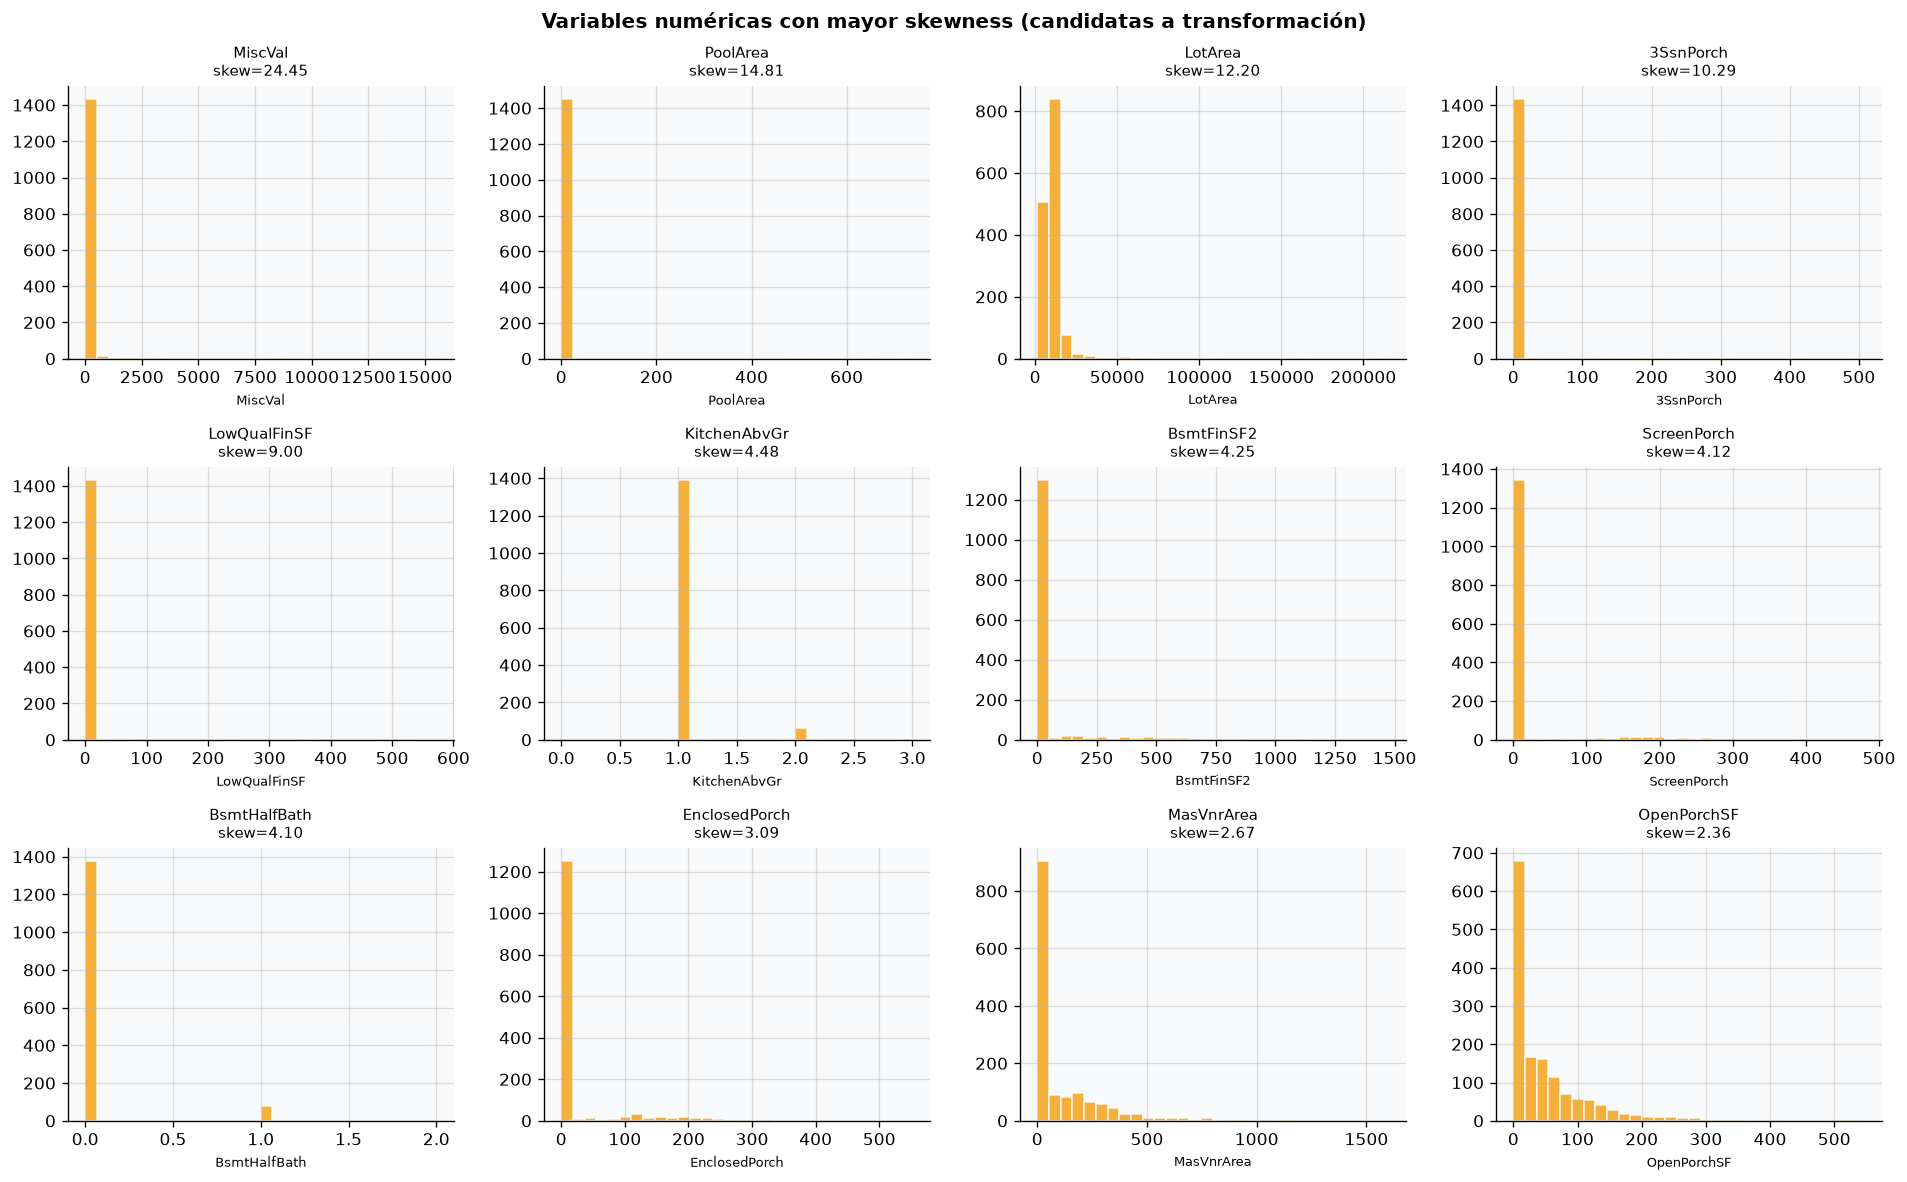

In [32]:
# ─── 4.3 DISTRIBUCIONES — SKEWNESS DE NUMÉRICAS ─────────────────────────────
skewness = train[num_features].apply(lambda x: skew(x.dropna())).sort_values(ascending=False)
high_skew = skewness[skewness.abs() > 0.75]

print(f'Variables con |skewness| > 0.75: {len(high_skew)} (candidatas a log-transform)')
print(high_skew.to_string())

# Visualizar las 12 más sesgadas
top_skew = skewness.abs().sort_values(ascending=False).head(12).index
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
fig.suptitle('Variables numéricas con mayor skewness (candidatas a transformación)', fontweight='bold')

for ax, feat in zip(axes.ravel(), top_skew):
    data = train[feat].dropna()
    ax.hist(data, bins=30, color=COLOR_ACCENT, edgecolor='white', alpha=0.8)
    ax.set_title(f'{feat}\nskew={skewness[feat]:.2f}', fontsize=9)
    ax.set_xlabel(feat, fontsize=8)

plt.tight_layout()
plt.savefig('../img/eda_05_skewness.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 5 · Variables Categóricas — Frecuencia e Impacto en Precio

In [33]:
# ─── 5.1 VARIABLES CATEGÓRICAS MÁS IMPORTANTES ──────────────────────────────
# Calculamos el impacto (varianza en SalePrice que explica cada categoría)
cat_impact = {}
for col in cat_cols:
    groups = train.groupby(col)['SalePrice'].mean()
    cat_impact[col] = groups.max() - groups.min()  # rango de medias

cat_impact_sorted = pd.Series(cat_impact).sort_values(ascending=False)

print('Variables categóricas ordenadas por impacto en SalePrice (rango de medias por grupo):')
display(cat_impact_sorted.to_frame('Rango_Medias').style
        .background_gradient(cmap='YlOrRd')
        .format({'Rango_Medias': '${:,.0f}'}))

Variables categóricas ordenadas por impacto en SalePrice (rango de medias por grupo):


,Rango_Medias
PoolQC,"$288,010"
ExterQual,"$279,376"
RoofMatl,"$253,250"
Neighborhood,"$236,719"
Condition2,"$228,250"
KitchenQual,"$222,989"
Exterior2nd,"$214,000"
BsmtQual,"$211,349"
FireplaceQu,"$207,948"
Exterior1st,"$191,000"


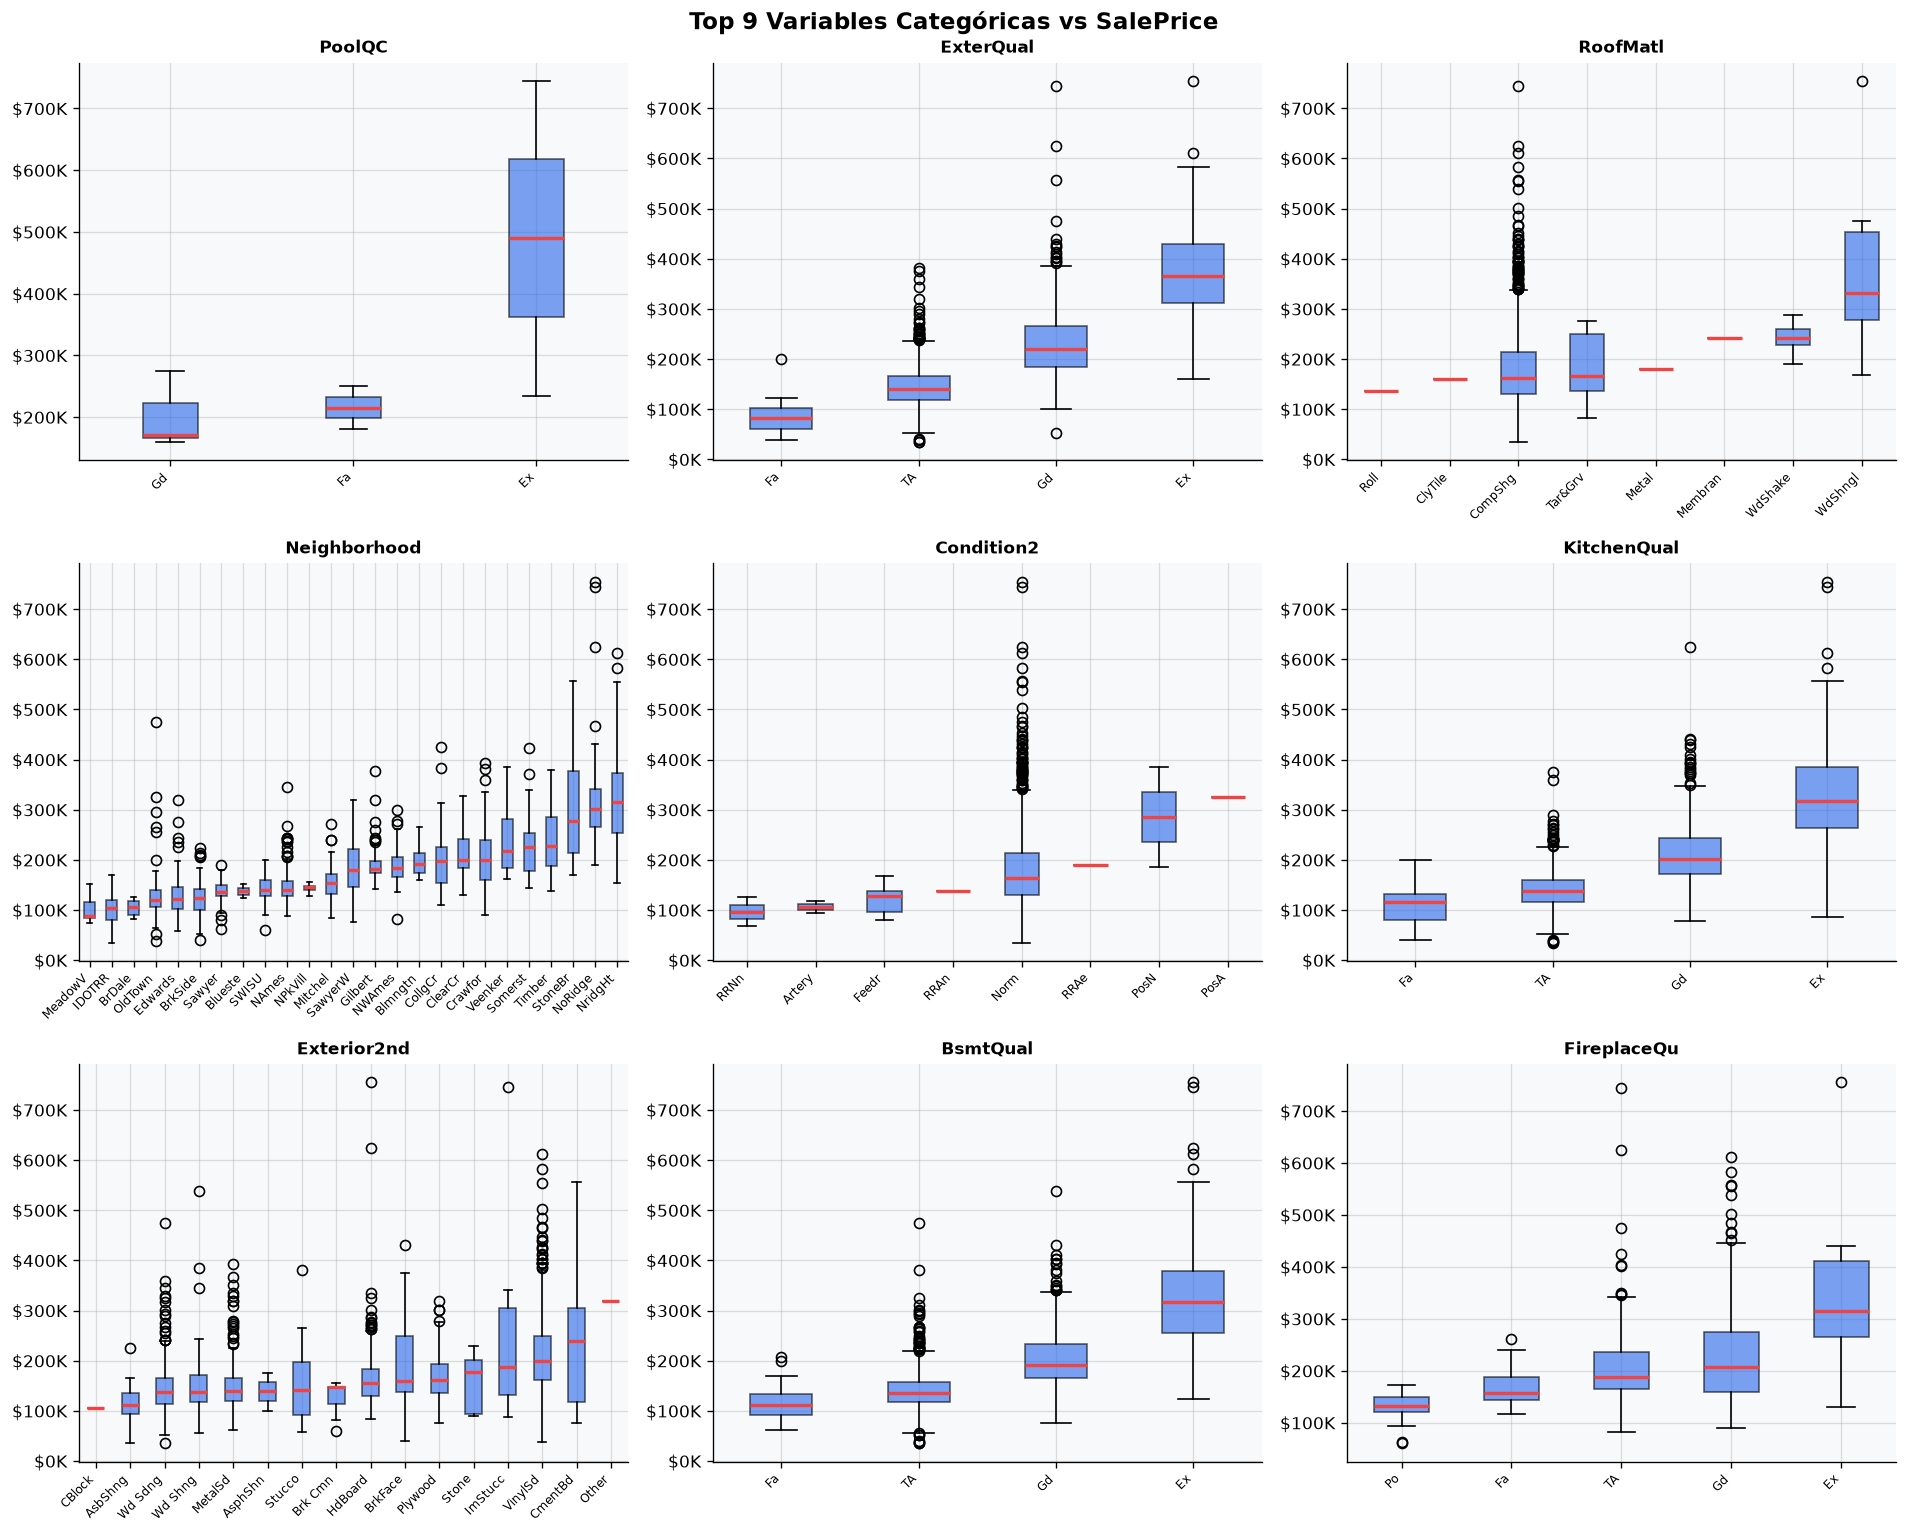

In [34]:
# ─── 5.2 BOXPLOTS — TOP 9 CATEGÓRICAS POR IMPACTO ──────────────────────────
top9_cat = cat_impact_sorted.head(9).index.tolist()

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
fig.suptitle('Top 9 Variables Categóricas vs SalePrice', fontsize=14, fontweight='bold')

for ax, feat in zip(axes.ravel(), top9_cat):
    order = train.groupby(feat)['SalePrice'].median().sort_values().index
    data_plot = [(train.loc[train[feat]==cat, 'SalePrice'].values) for cat in order]
    # bp = ax.boxplot(data_plot, labels=order, patch_artist=True, notch=False,
    #                 medianprops=dict(color=COLOR_DANGER, linewidth=2))
    bp = ax.boxplot(data_plot, tick_labels=order, patch_artist=True, notch=False, 
                    medianprops=dict(color=COLOR_DANGER, linewidth=2))
    for patch in bp['boxes']:
        patch.set_facecolor(COLOR_MAIN)
        patch.set_alpha(0.6)
    ax.set_title(feat, fontweight='bold', fontsize=10)
    ax.set_xticklabels(order, rotation=45, ha='right', fontsize=7)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))

plt.tight_layout()
plt.savefig('../img/eda_06_cat_boxplots.png', bbox_inches='tight', dpi=120)
plt.show()

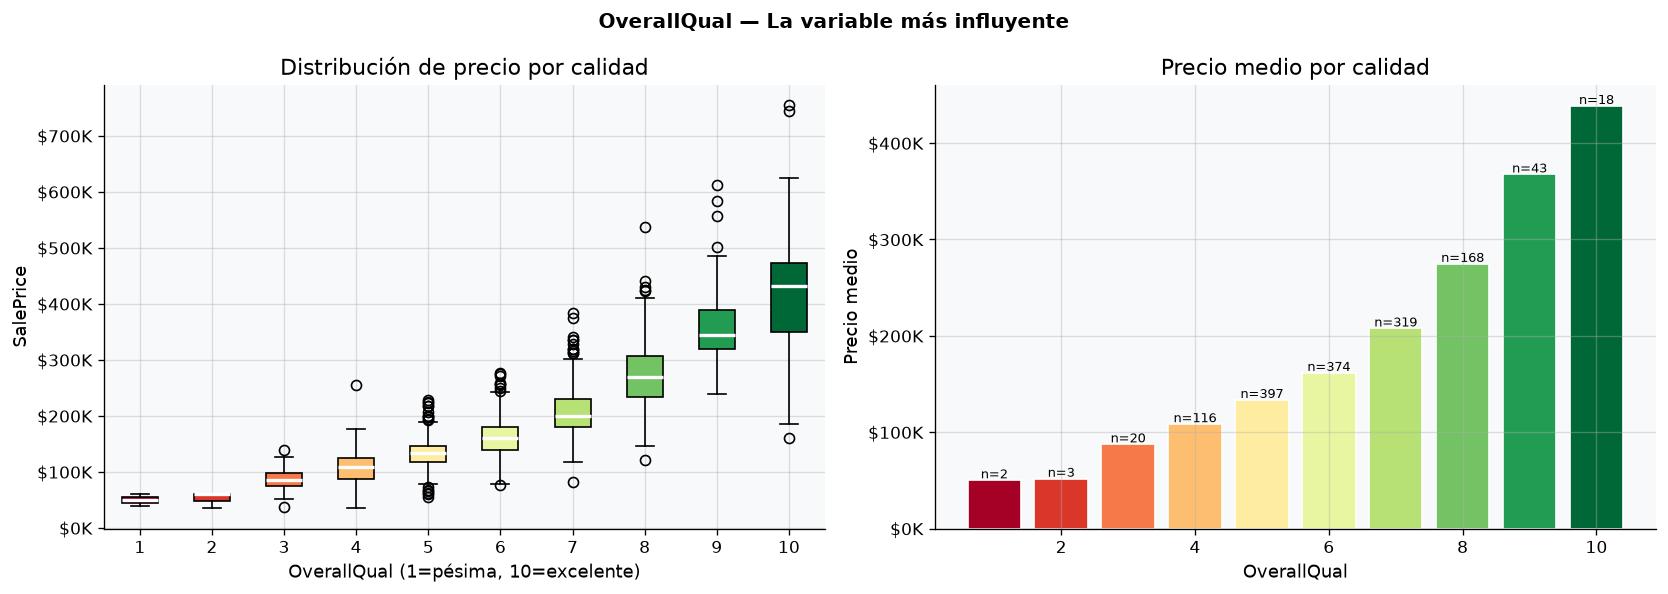

In [35]:
# ─── 5.3 OVERALL QUALITY — la más poderosa ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('OverallQual — La variable más influyente', fontweight='bold')

# Boxplot por calidad
ax = axes[0]
oq_data = [train.loc[train['OverallQual']==q, 'SalePrice'].values for q in range(1, 11)]
bp = ax.boxplot(oq_data, tick_labels=range(1, 11), patch_artist=True,
                medianprops=dict(color='white', linewidth=2))
cmap = plt.cm.RdYlGn
for i, patch in enumerate(bp['boxes']):
    patch.set_facecolor(cmap(i / 9))
ax.set_xlabel('OverallQual (1=pésima, 10=excelente)')
ax.set_ylabel('SalePrice')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))
ax.set_title('Distribución de precio por calidad')

# Precio medio por calidad
ax = axes[1]
mean_by_qual = train.groupby('OverallQual')['SalePrice'].mean()
count_by_qual = train.groupby('OverallQual')['SalePrice'].count()
colors = [cmap(i / 9) for i in range(10)]
bars = ax.bar(mean_by_qual.index, mean_by_qual.values, color=colors, edgecolor='white')
for bar, cnt in zip(bars, count_by_qual.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2000,
            f'n={cnt}', ha='center', fontsize=8)
ax.set_xlabel('OverallQual')
ax.set_ylabel('Precio medio')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))
ax.set_title('Precio medio por calidad')

plt.tight_layout()
plt.savefig('../img/eda_07_overallqual.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 6 · Outliers Críticos

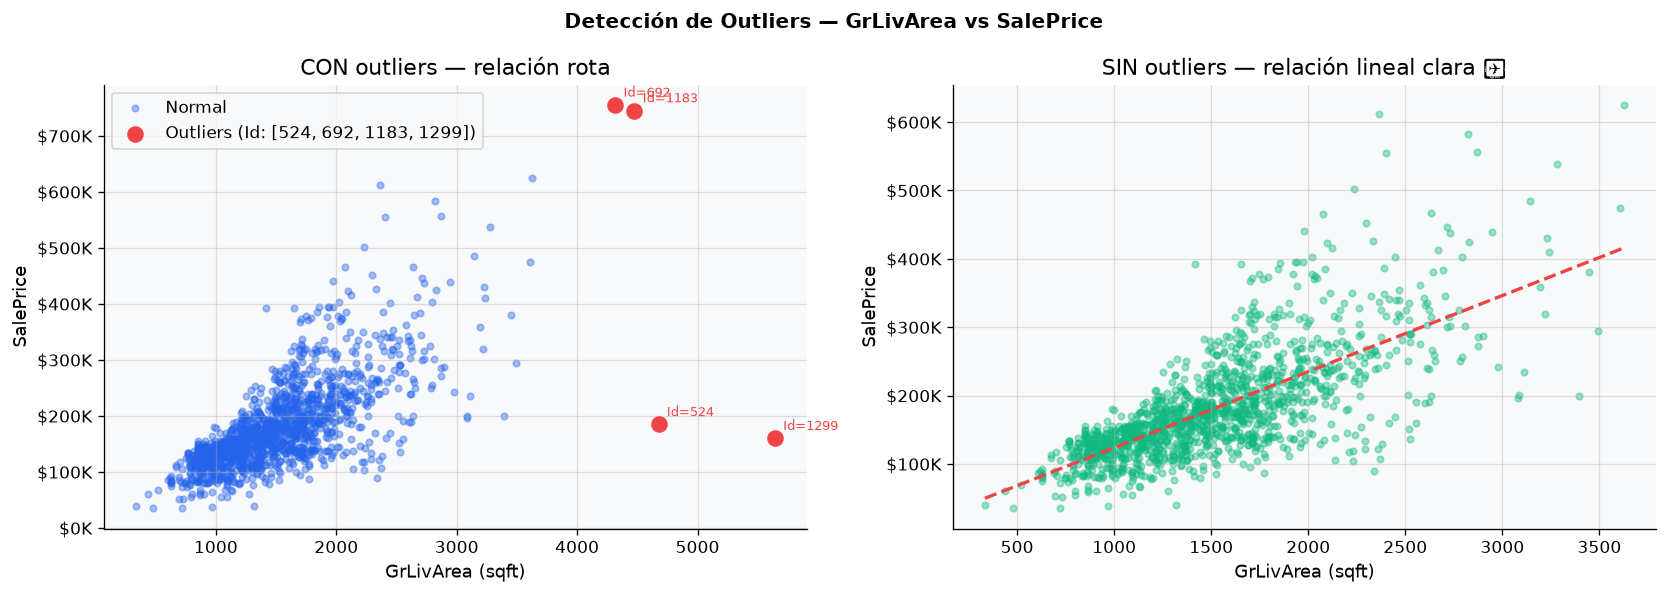

🔴 Casas con GrLivArea > 4000: Id = [524, 692, 1183, 1299]
   Criterio de De Cock: se eliminan TODAS por área, sin mirar el precio
   ACCIÓN: train = train[train["GrLivArea"] < 4000]


In [37]:
# ─── OUTLIERS EN GRLIV AREA (el más documentado) ──────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Detección de Outliers — GrLivArea vs SalePrice', fontweight='bold')

# IDs de outliers conocidos
outlier_mask = train['GrLivArea'] > 4000  # criterio De Cock: solo por área
outlier_ids = train.loc[outlier_mask, 'Id'].tolist()

ax = axes[0]
ax.scatter(train.loc[~outlier_mask, 'GrLivArea'],
           train.loc[~outlier_mask, 'SalePrice'],
           alpha=0.4, s=15, color=COLOR_MAIN, label='Normal')
ax.scatter(train.loc[outlier_mask, 'GrLivArea'],
           train.loc[outlier_mask, 'SalePrice'],
           alpha=1, s=80, color=COLOR_DANGER, label=f'Outliers (Id: {outlier_ids})', zorder=5)
for idx in train[outlier_mask].index:
    ax.annotate(f'Id={train.loc[idx,"Id"]}',
                (train.loc[idx,'GrLivArea'], train.loc[idx,'SalePrice']),
                textcoords='offset points', xytext=(5, 5), fontsize=8, color=COLOR_DANGER)
ax.set_xlabel('GrLivArea (sqft)')
ax.set_ylabel('SalePrice')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))
ax.set_title('CON outliers — relación rota')
ax.legend()

ax = axes[1]
train_clean = train[~outlier_mask]
ax.scatter(train_clean['GrLivArea'], train_clean['SalePrice'],
           alpha=0.4, s=15, color=COLOR_SUCCESS)
z = np.polyfit(train_clean['GrLivArea'], train_clean['SalePrice'], 1)
p = np.poly1d(z)
x_line = np.linspace(train_clean['GrLivArea'].min(), train_clean['GrLivArea'].max(), 100)
ax.plot(x_line, p(x_line), color=COLOR_DANGER, linewidth=2, linestyle='--')
ax.set_xlabel('GrLivArea (sqft)')
ax.set_ylabel('SalePrice')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))
ax.set_title('SIN outliers — relación lineal clara ✅')

plt.tight_layout()
plt.show()

print(f'🔴 Casas con GrLivArea > 4000: Id = {outlier_ids}')
print(f'   Criterio de De Cock: se eliminan TODAS por área, sin mirar el precio')
print(f'   ACCIÓN: train = train[train["GrLivArea"] < 4000]')

Outliers por variable (|z-score| > 3):
GrLivArea      16
TotalBsmtSF    10
1stFlrSF       12
LotArea        13


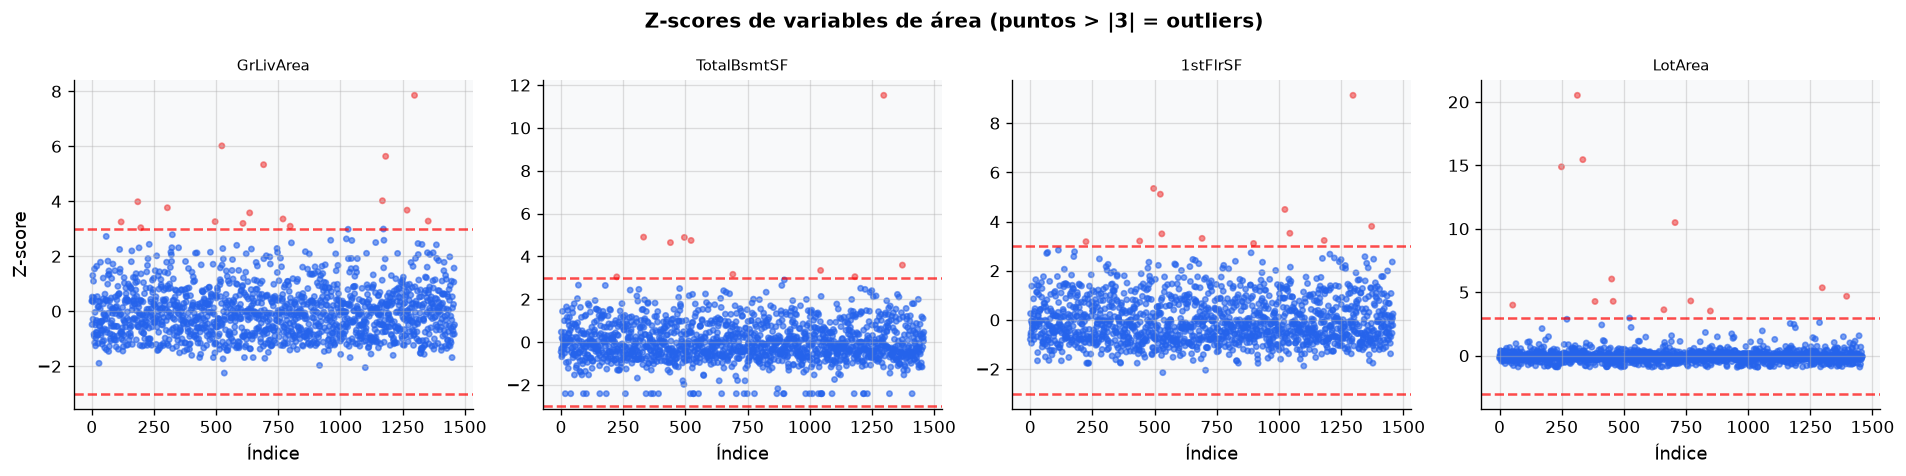

In [38]:
# ─── 6.2 DETECCIÓN MULTIVARIADA CON Z-SCORE ─────────────────────────────────
from scipy.stats import zscore

key_features = ['GrLivArea', 'TotalBsmtSF', '1stFlrSF', 'LotArea']
z_scores = train[key_features].apply(zscore)
n_outliers_per_feat = (z_scores.abs() > 3).sum()

print('Outliers por variable (|z-score| > 3):')
print(n_outliers_per_feat.to_string())

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
fig.suptitle('Z-scores de variables de área (puntos > |3| = outliers)', fontweight='bold')

for ax, feat in zip(axes, key_features):
    z = z_scores[feat]
    colors_z = [COLOR_DANGER if abs(v) > 3 else COLOR_MAIN for v in z]
    ax.scatter(range(len(z)), z, c=colors_z, s=10, alpha=0.6)
    ax.axhline(3,  color='red', linestyle='--', alpha=0.7)
    ax.axhline(-3, color='red', linestyle='--', alpha=0.7)
    ax.set_title(feat, fontsize=9)
    ax.set_xlabel('Índice')
    if ax == axes[0]:
        ax.set_ylabel('Z-score')

plt.tight_layout()
plt.savefig('../img/eda_09_zscores.png', bbox_inches='tight', dpi=120)
plt.show()

---
## 7 · Análisis por Vecindario (`Neighborhood`)

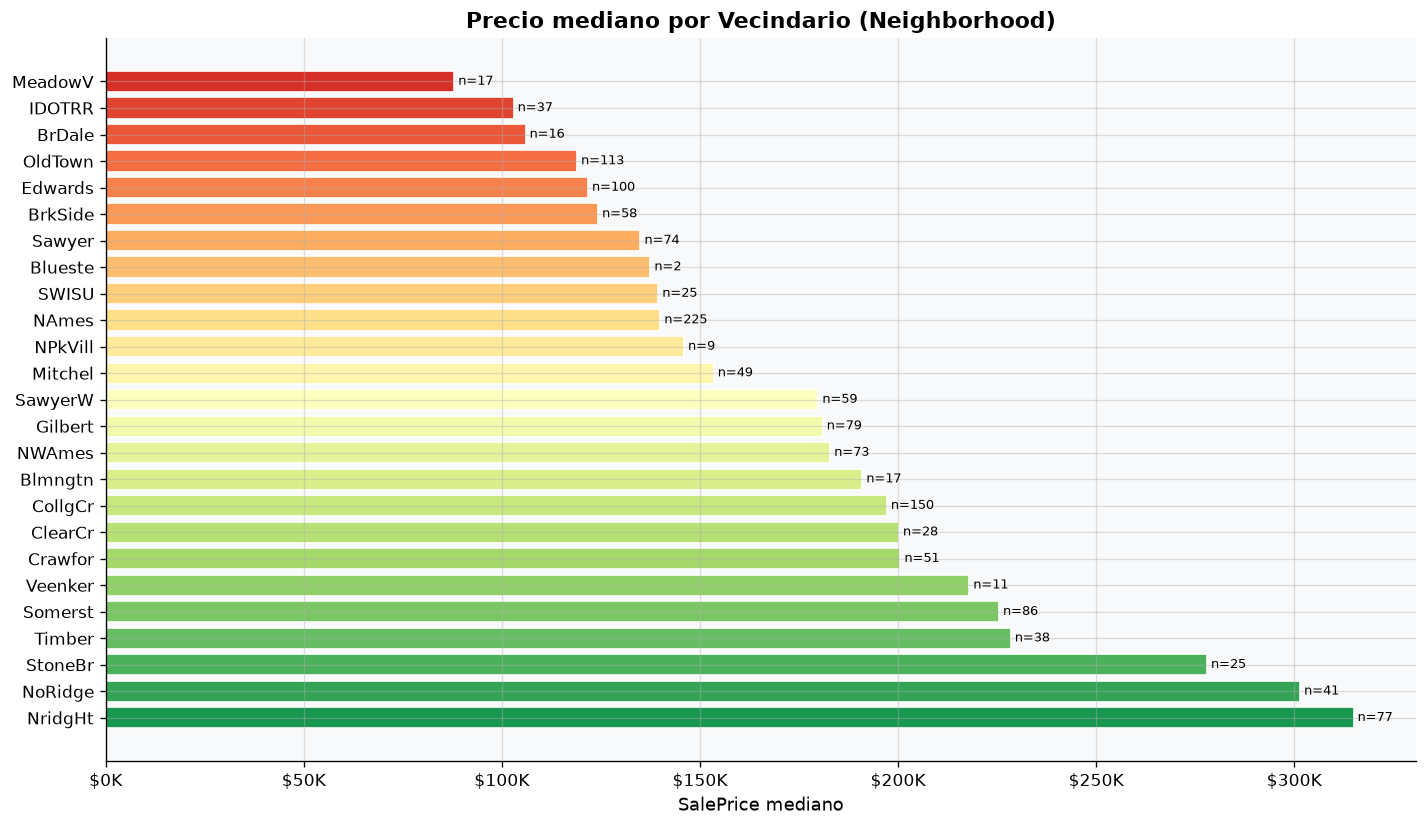


💡 INSIGHT: Neighborhood es una variable muy poderosa.
   Rango de precios medianos:
   - Más caro:   NridgHt → $315,000
   - Más barato: MeadowV → $88,000
   - Ratio:      3.6x


In [39]:
# ─── 7.1 PRECIO MEDIANO POR VECINDARIO ──────────────────────────────────────
neigh_stats = train.groupby('Neighborhood').agg(
    Precio_Mediano=('SalePrice', 'median'),
    Precio_Medio=('SalePrice', 'mean'),
    N_Casas=('SalePrice', 'count'),
    Precio_Max=('SalePrice', 'max'),
).sort_values('Precio_Mediano', ascending=False)

fig, ax = plt.subplots(figsize=(12, 7))
colors_neigh = plt.cm.RdYlGn(np.linspace(0.1, 0.9, len(neigh_stats)))
bars = ax.barh(neigh_stats.index, neigh_stats['Precio_Mediano'],
               color=colors_neigh[::-1], edgecolor='white')

for bar, cnt in zip(bars, neigh_stats['N_Casas']):
    ax.text(bar.get_width() + 1000, bar.get_y() + bar.get_height()/2,
            f'n={cnt}', va='center', fontsize=7.5)

ax.set_xlabel('SalePrice mediano')
ax.set_title('Precio mediano por Vecindario (Neighborhood)', fontweight='bold')
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))
plt.tight_layout()
plt.savefig('../img/eda_10_neighborhood.png', bbox_inches='tight', dpi=120)
plt.show()

print('\n💡 INSIGHT: Neighborhood es una variable muy poderosa.')
print('   Rango de precios medianos:')
print(f'   - Más caro:   {neigh_stats.index[0]} → ${neigh_stats["Precio_Mediano"].iloc[0]:,.0f}')
print(f'   - Más barato: {neigh_stats.index[-1]} → ${neigh_stats["Precio_Mediano"].iloc[-1]:,.0f}')
print(f'   - Ratio:      {neigh_stats["Precio_Mediano"].iloc[0]/neigh_stats["Precio_Mediano"].iloc[-1]:.1f}x')

---
## 8 · Variables Temporales

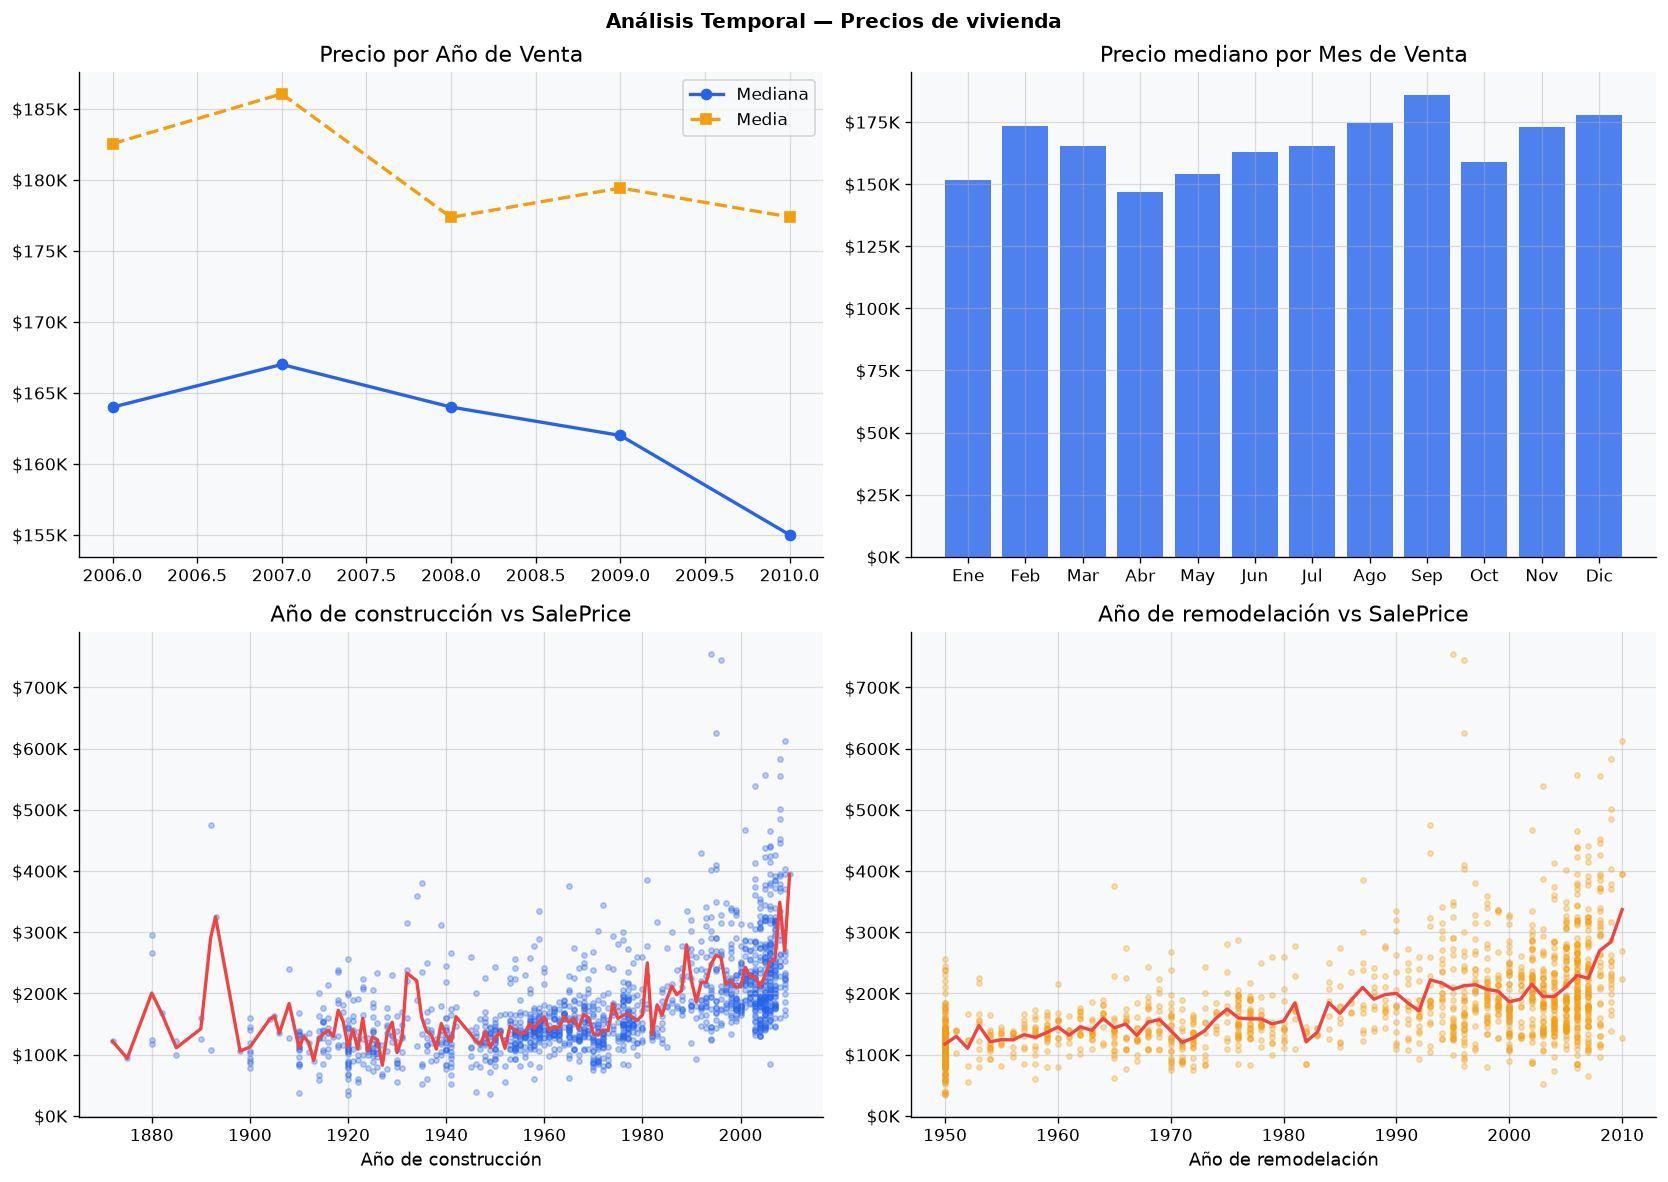

💡 INSIGHTS TEMPORALES:
   - Crisis 2008 visible en YrSold: ligera caída en 2008-2010
   - Casas nuevas (~2000+) tienen precios notablemente más altos
   - Meses de primavera/verano (May-Jul) tienen precios ligeramente mayores
   - FEATURES A CREAR: HouseAge, RemodAge, IsNew


In [40]:
# ─── 8.1 TENDENCIA TEMPORAL ──────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Análisis Temporal — Precios de vivienda', fontweight='bold')

# Precio por año de venta
ax = axes[0, 0]
year_data = train.groupby('YrSold')['SalePrice'].agg(['median','mean','count'])
ax.plot(year_data.index, year_data['median'], 'o-', color=COLOR_MAIN, label='Mediana', linewidth=2)
ax.plot(year_data.index, year_data['mean'],   's--', color=COLOR_ACCENT, label='Media', linewidth=2)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))
ax.set_title('Precio por Año de Venta')
ax.legend()

# Precio por mes de venta
ax = axes[0, 1]
month_data = train.groupby('MoSold')['SalePrice'].median()
ax.bar(month_data.index, month_data.values, color=COLOR_MAIN, alpha=0.8)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Ene','Feb','Mar','Abr','May','Jun','Jul','Ago','Sep','Oct','Nov','Dic'])
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))
ax.set_title('Precio mediano por Mes de Venta')

# Año de construcción vs precio
ax = axes[1, 0]
ax.scatter(train['YearBuilt'], train['SalePrice'], alpha=0.3, s=10, color=COLOR_MAIN)
yr_means = train.groupby('YearBuilt')['SalePrice'].mean()
ax.plot(yr_means.index, yr_means.values, color=COLOR_DANGER, linewidth=2)
ax.set_xlabel('Año de construcción')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))
ax.set_title('Año de construcción vs SalePrice')

# Año de remodelación vs precio
ax = axes[1, 1]
ax.scatter(train['YearRemodAdd'], train['SalePrice'], alpha=0.3, s=10, color=COLOR_ACCENT)
rmd_means = train.groupby('YearRemodAdd')['SalePrice'].mean()
ax.plot(rmd_means.index, rmd_means.values, color=COLOR_DANGER, linewidth=2)
ax.set_xlabel('Año de remodelación')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))
ax.set_title('Año de remodelación vs SalePrice')

plt.tight_layout()
plt.savefig('../img/eda_11_temporal.png', bbox_inches='tight', dpi=120)
plt.show()

print('💡 INSIGHTS TEMPORALES:')
print('   - Crisis 2008 visible en YrSold: ligera caída en 2008-2010')
print('   - Casas nuevas (~2000+) tienen precios notablemente más altos')
print('   - Meses de primavera/verano (May-Jul) tienen precios ligeramente mayores')
print('   - FEATURES A CREAR: HouseAge, RemodAge, IsNew')

---
## 9 · Matriz de Correlación Avanzada

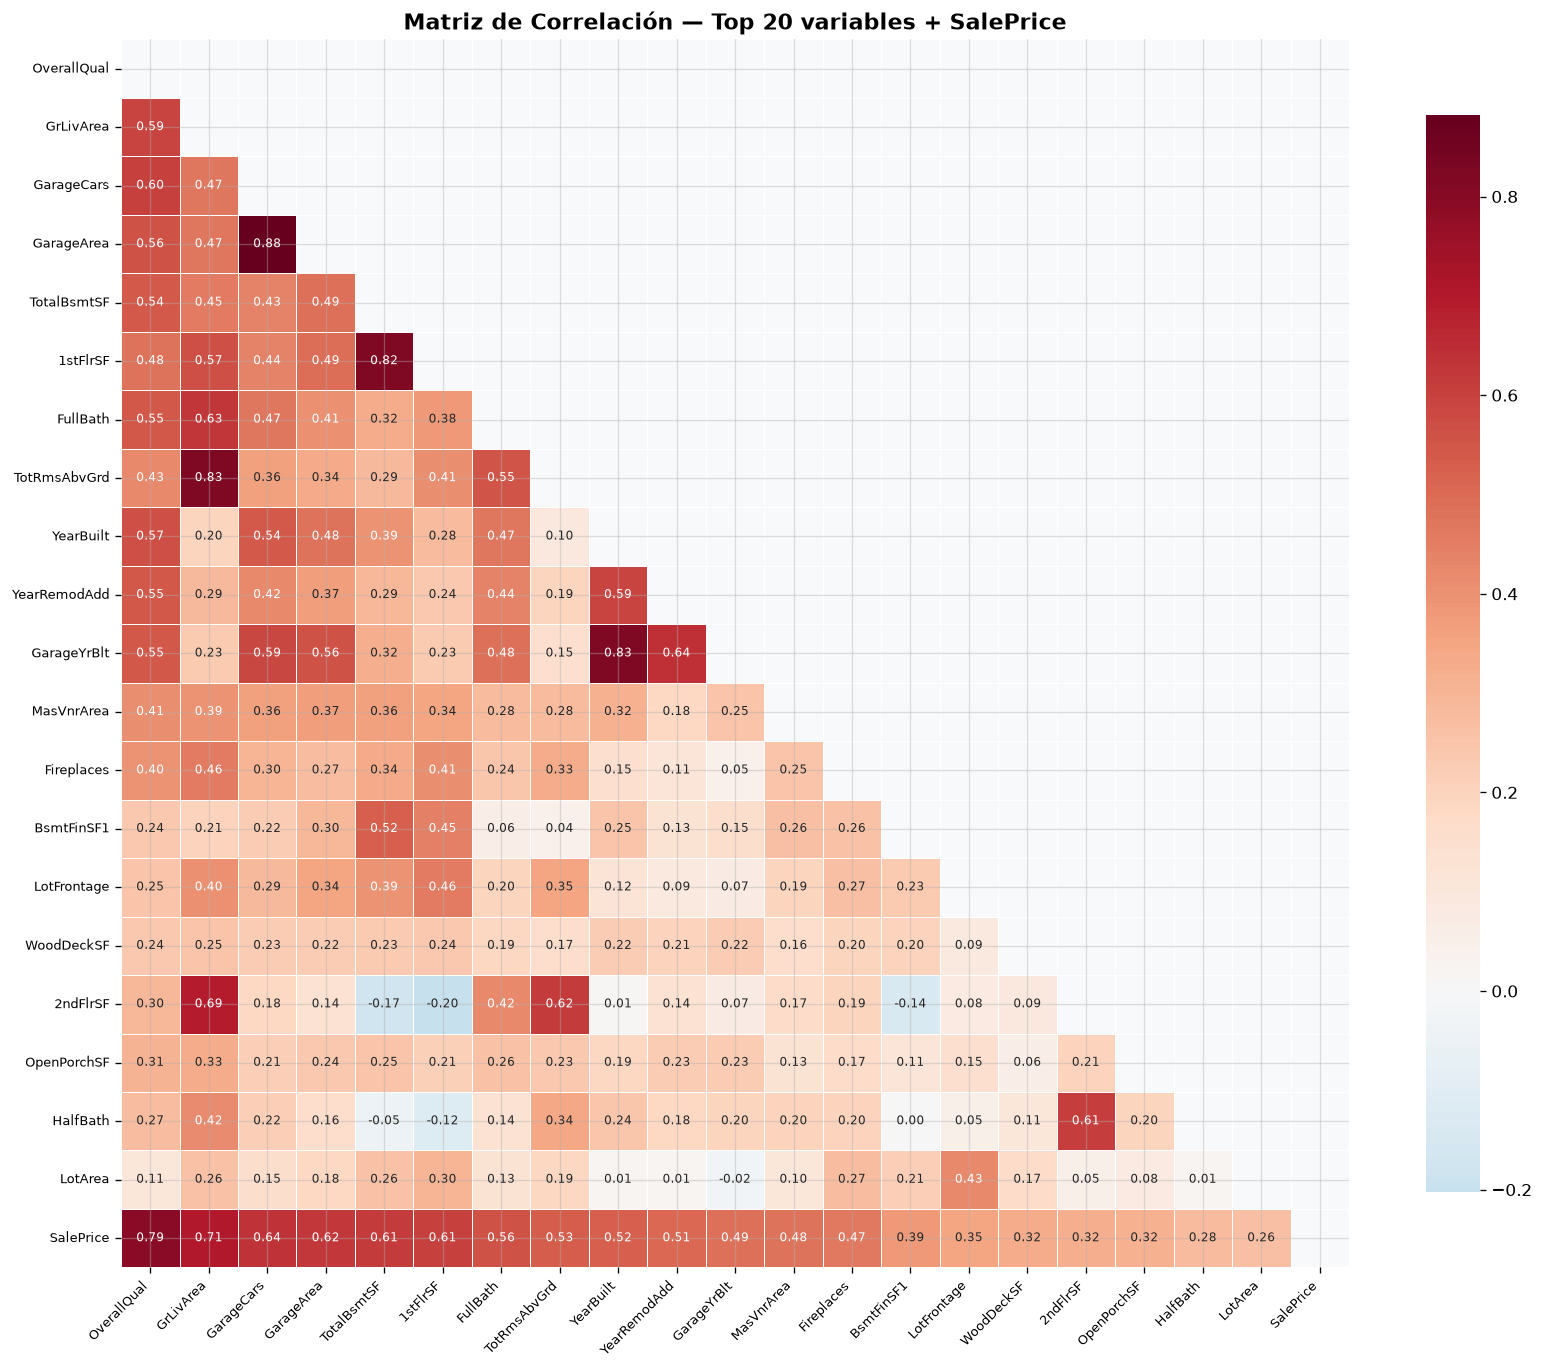


⚠️  VARIABLES ALTAMENTE CORRELACIONADAS ENTRE SÍ (|r| > 0.8):
   GarageArea           ↔ GarageCars            r = +0.882
   GarageYrBlt          ↔ YearBuilt             r = +0.826
   TotRmsAbvGrd         ↔ GrLivArea             r = +0.825
   1stFlrSF             ↔ TotalBsmtSF           r = +0.820

💡 Modelos como Lasso manejarán esto automáticamente.
   Para tree-based (XGBoost/LGBM) la multicolinealidad no es problema.


In [41]:
# ─── 9.1 HEATMAP — TOP 20 VARIABLES MÁS CORRELACIONADAS ────────────────────
top20 = corr_sorted.head(20).index.tolist() + ['SalePrice']
corr_matrix = train[top20].corr()

fig, ax = plt.subplots(figsize=(14, 12))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=0.5, ax=ax,
            annot_kws={'size': 7},
            cbar_kws={'shrink': 0.8})

ax.set_title('Matriz de Correlación — Top 20 variables + SalePrice', fontweight='bold', fontsize=13)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.savefig('../img/eda_12_heatmap.png', bbox_inches='tight', dpi=120)
plt.show()

# Variables multicolineales (correlación > 0.8 entre ellas)
print('\n⚠️  VARIABLES ALTAMENTE CORRELACIONADAS ENTRE SÍ (|r| > 0.8):')
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = [(col, row, upper.loc[row, col])
                   for col in upper.columns for row in upper.index
                   if abs(upper.loc[row, col]) > 0.8 and row != 'SalePrice' and col != 'SalePrice']
for a, b, r in sorted(high_corr_pairs, key=lambda x: abs(x[2]), reverse=True):
    print(f'   {a:<20} ↔ {b:<20}  r = {r:+.3f}')

print('\n💡 Modelos como Lasso manejarán esto automáticamente.')
print('   Para tree-based (XGBoost/LGBM) la multicolinealidad no es problema.')

---
## 10 · Resumen Ejecutivo y Decisiones

In [42]:
# ─── 10.1 RESUMEN FINAL ──────────────────────────────────────────────────────
print('=' * 70)
print('  RESUMEN EJECUTIVO — EDA House Prices Kaggle')
print('=' * 70)

print('''
📊 DATASET
  • 1460 registros de entrenamiento, 1459 de test
  • 79 variables: 36 numéricas, 43 categóricas
  • Variable objetivo: SalePrice (precio de venta en USD)

🎯 TARGET (SalePrice)
  ✅ Distribución con sesgo a la derecha → aplicar log1p(SalePrice)
  ✅ Rango: $34,900 – $755,000  |  Mediana: ~$163,000

❌ OUTLIERS A ELIMINAR
  • Id 524 y 1299: GrLivArea > 4000 pero SalePrice < $300K (granjas)
  • Eliminar antes del entrenamiento: train = train[train.index no en [524, 1299]]

🔧 VALORES FALTANTES — ESTRATEGIA
  • 19 variables rellenar con "None" (el NaN significa "no tiene")
  • 8 variables rellenar con 0
  • LotFrontage: mediana por Neighborhood (fuerte relación geográfica)
  • MSZoning, Utilities, etc.: moda

⚙️  FEATURE ENGINEERING RECOMENDADO
  • TotalSF        = TotalBsmtSF + 1stFlrSF + 2ndFlrSF
  • TotalBathrooms = FullBath + 0.5*HalfBath + BsmtFullBath + 0.5*BsmtHalfBath
  • HouseAge       = YrSold - YearBuilt
  • RemodAge       = YrSold - YearRemodAdd
  • IsNew          = (YearBuilt == YrSold)
  • TotalPorch     = suma de todos los porches
  • HasPool, HasGarage, HasBsmt, HasFireplace (flags binarios)

🏷️  ENCODING
  • OrdinalEncoder para variables de calidad (Ex>Gd>TA>Fa>Po)
  • OneHotEncoder para nominales (MSSubClass como str, Neighborhood...)
  • LabelEncoder no recomendado para nominales sin orden

📐 TRANSFORMACIONES
  • log1p() en variables con skewness > 0.75 (principalmente áreas)
  • StandardScaler para modelos lineales
  • Tree-based (XGBoost, LightGBM) no requieren scaling

🏆 TOP VARIABLES POR PODER PREDICTIVO
  1. OverallQual  (r=0.79) — calidad general
  2. GrLivArea    (r=0.71) — área habitable
  3. GarageCars   (r=0.64) — capacidad del garaje
  4. GarageArea   (r=0.62) — área del garaje
  5. TotalBsmtSF  (r=0.61) — área del sótano
  6. Neighborhood          — variable categórica clave
  7. YearBuilt    (r=0.52) — antigüedad

🎯 MODELOS RECOMENDADOS (siguiente fase)
  1. Ridge / Lasso / ElasticNet  → baseline sólido (~RMSLE 0.13)
  2. XGBoost + LightGBM          → ~RMSLE 0.12
  3. Ensemble/Blending           → objetivo <0.11
''')
print('=' * 70)
print('✅ EDA completado. Siguiente paso: Preprocesamiento + Feature Engineering')
print('=' * 70)

  RESUMEN EJECUTIVO — EDA House Prices Kaggle

📊 DATASET
  • 1460 registros de entrenamiento, 1459 de test
  • 79 variables: 36 numéricas, 43 categóricas
  • Variable objetivo: SalePrice (precio de venta en USD)

🎯 TARGET (SalePrice)
  ✅ Distribución con sesgo a la derecha → aplicar log1p(SalePrice)
  ✅ Rango: $34,900 – $755,000  |  Mediana: ~$163,000

❌ OUTLIERS A ELIMINAR
  • Id 524 y 1299: GrLivArea > 4000 pero SalePrice < $300K (granjas)
  • Eliminar antes del entrenamiento: train = train[train.index no en [524, 1299]]

🔧 VALORES FALTANTES — ESTRATEGIA
  • 19 variables rellenar con "None" (el NaN significa "no tiene")
  • 8 variables rellenar con 0
  • LotFrontage: mediana por Neighborhood (fuerte relación geográfica)
  • MSZoning, Utilities, etc.: moda

⚙️  FEATURE ENGINEERING RECOMENDADO
  • TotalSF        = TotalBsmtSF + 1stFlrSF + 2ndFlrSF
  • TotalBathrooms = FullBath + 0.5*HalfBath + BsmtFullBath + 0.5*BsmtHalfBath
  • HouseAge       = YrSold - YearBuilt
  • RemodAge       = 

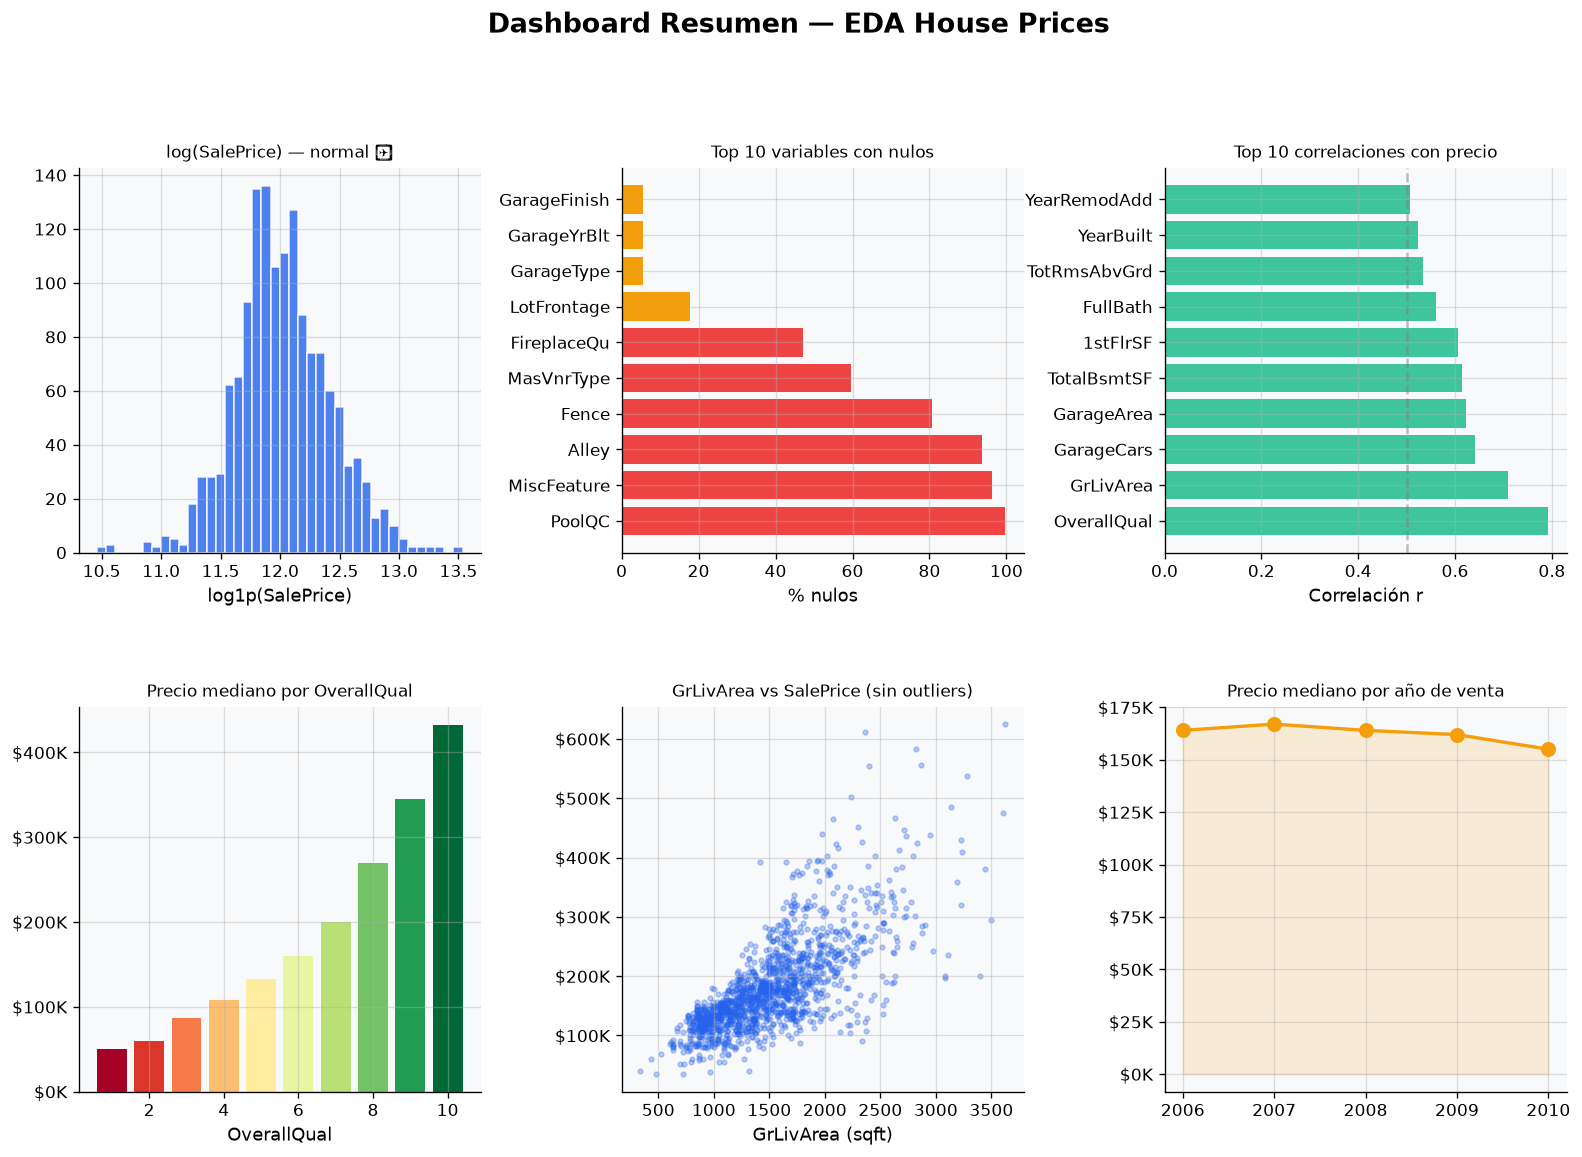

📊 Dashboard guardado como eda_13_dashboard_resumen.png


In [43]:
# ─── 10.2 DASHBOARD RESUMEN VISUAL ──────────────────────────────────────────
fig = plt.figure(figsize=(16, 10))
fig.suptitle('Dashboard Resumen — EDA House Prices', fontsize=16, fontweight='bold', y=1.01)

gs = fig.add_gridspec(2, 3, hspace=0.4, wspace=0.35)

# Panel 1: Distribución target (log)
ax1 = fig.add_subplot(gs[0, 0])
ax1.hist(np.log1p(train['SalePrice']), bins=40, color=COLOR_MAIN, alpha=0.8, edgecolor='white')
ax1.set_title('log(SalePrice) — normal ✅', fontsize=10)
ax1.set_xlabel('log1p(SalePrice)')

# Panel 2: Nulos top 10
ax2 = fig.add_subplot(gs[0, 1])
miss10 = miss_train.head(10)
ax2.barh(miss10.index, miss10['Porcentaje'],
         color=[COLOR_DANGER if p > 20 else COLOR_ACCENT for p in miss10['Porcentaje']])
ax2.set_title('Top 10 variables con nulos', fontsize=10)
ax2.set_xlabel('% nulos')

# Panel 3: Top 10 correlaciones
ax3 = fig.add_subplot(gs[0, 2])
top10_corr = corr_sorted.head(10)
ax3.barh(top10_corr.index, corr_with_target[top10_corr.index],
         color=COLOR_SUCCESS, alpha=0.8)
ax3.set_title('Top 10 correlaciones con precio', fontsize=10)
ax3.set_xlabel('Correlación r')
ax3.axvline(0.5, color='gray', linestyle='--', alpha=0.5)

# Panel 4: Precio por OverallQual
ax4 = fig.add_subplot(gs[1, 0])
mean_q = train.groupby('OverallQual')['SalePrice'].median()
cmap_q = plt.cm.RdYlGn
ax4.bar(mean_q.index, mean_q.values, color=[cmap_q(i/9) for i in range(10)])
ax4.set_title('Precio mediano por OverallQual', fontsize=10)
ax4.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))
ax4.set_xlabel('OverallQual')

# Panel 5: GrLivArea scatter
ax5 = fig.add_subplot(gs[1, 1])
ax5.scatter(train_clean['GrLivArea'], train_clean['SalePrice'],
            alpha=0.3, s=8, color=COLOR_MAIN)
ax5.set_title('GrLivArea vs SalePrice (sin outliers)', fontsize=10)
ax5.set_xlabel('GrLivArea (sqft)')
ax5.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))

# Panel 6: Precio por año
ax6 = fig.add_subplot(gs[1, 2])
yr_med = train.groupby('YrSold')['SalePrice'].median()
ax6.plot(yr_med.index, yr_med.values, 'o-', color=COLOR_ACCENT, linewidth=2, markersize=8)
ax6.fill_between(yr_med.index, yr_med.values, alpha=0.15, color=COLOR_ACCENT)
ax6.set_title('Precio mediano por año de venta', fontsize=10)
ax6.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1000:.0f}K'))

plt.tight_layout()
plt.savefig('../img/eda_13_dashboard_resumen.png', bbox_inches='tight', dpi=120)
plt.show()
print('📊 Dashboard guardado como eda_13_dashboard_resumen.png')